# Explainable and Robust Diamond Price Prediction Using Machine Learning with What-If Analysis

## Project Overview

This project develops a machine-learning-based framework for diamond price prediction using a richer set of diamond characteristics.

The study investigates the effect of feature enrichment through systematic feature ablation, compares multiple regression models, evaluates model robustness using cross-validation, explains predictions using SHAP, and demonstrates controlled What-If analysis for individual diamond attributes.

## Research Objective

The primary objective of this study is to investigate how the inclusion of richer diamond characteristics affects the performance of machine-learning-based diamond price prediction.

The study also evaluates multiple regression models, validates their performance using cross-validation, explains model predictions using SHAP, and demonstrates controlled What-If analysis for individual diamond attributes.

## Research Questions

1. How much does prediction performance improve when moving from traditional 4C characteristics to a richer set of diamond features?

2. What is the contribution of dimensions and physical/quality characteristics to diamond price prediction?

3. How do Random Forest, Gradient Boosting, and Extra Trees compare when using the complete feature set?

4. How consistent is model performance across different cross-validation folds?

5. Which features contribute most strongly to individual model predictions?

6. How can What-If analysis be used to examine changes in model-predicted diamond prices under controlled feature changes?

## Literature-Based Research Gap

A review of previous diamond price prediction studies identified several recurring limitations and opportunities:

1. **Limited feature coverage:** Many studies rely on conventional diamond characteristics, particularly the 4C attributes.

2. **Feature enrichment:** Recent studies show that feature engineering, interaction terms, and additional diamond characteristics can affect prediction performance.

3. **Generalization concerns:** Many studies rely on a single dataset or market, which can limit the assessment of how well the models generalize to other diamond markets.

4. **Model-comparison focus:** A large part of the literature focuses on comparing algorithms, while a more complete framework can combine prediction, validation, feature analysis, and explainability.

5. **Interpretability:** Prediction accuracy alone does not explain why a particular diamond receives a specific estimated price.

6. **Practical interaction:** A controlled What-If analysis can allow users to examine how changing individual diamond characteristics affects the model's estimated price.

### Research Response

This study addresses these opportunities through a controlled experimental framework that combines:

- Feature-set ablation from traditional 4C features to a richer 17-feature representation.
- Comparison of Random Forest, Gradient Boosting, and Extra Trees.
- Five-fold cross-validation for robustness assessment.
- SHAP-based model explanation.
- Controlled What-If analysis for individual predictions.

## Dataset Description

The dataset used in this study is a diamond marketplace dataset containing detailed information about individual diamonds.

The original dataset contains **6,485 records and 18 features**. After removing **3 exact duplicate records**, the final dataset contains **6,482 records**.

The dataset includes traditional diamond characteristics as well as additional physical, quality, and market-related attributes.

### Feature Groups

**Traditional 4C-related features:**
- Carat Weight
- Cut
- Color
- Clarity

**Diamond dimensions:**
- Length
- Width
- Height
- Depth %
- Table %
- Length/Width Ratio

**Physical and quality characteristics:**
- Polish
- Symmetry
- Girdle
- Culet
- Fluorescence
- Shape

**Additional information:**
- Type
- Price

The target variable for this study is **Price**, while the remaining attributes are used as input features for machine-learning-based price prediction.

The dataset contains missing values, particularly in some categorical quality-related attributes. These missing values are handled through a preprocessing pipeline rather than being removed directly.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/diamonds (cleaned).csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (6485, 18)


In [2]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (6485, 18)

Column Names:
['Shape', 'Cut', 'Color', 'Clarity', 'Carat Weight', 'Length/Width Ratio', 'Depth %', 'Table %', 'Polish', 'Symmetry', 'Girdle', 'Culet', 'Length', 'Width', 'Height', 'Price', 'Type', 'Fluorescence']

Data Types:
Shape                     str
Cut                       str
Color                     str
Clarity                   str
Carat Weight          float64
Length/Width Ratio    float64
Depth %               float64
Table %               float64
Polish                    str
Symmetry                  str
Girdle                    str
Culet                     str
Length                float64
Width                 float64
Height                float64
Price                   int64
Type                      str
Fluorescence              str
dtype: object

First 5 Rows:


,Shape,Cut,Color,Clarity,Carat Weight,Length/Width Ratio,Depth %,Table %,Polish,Symmetry,Girdle,Culet,Length,Width,Height,Price,Type,Fluorescence
0,Cushion Modified,Ideal,F,VVS2,1.84,1.02,65.8,59.0,Excellent,Very Good,Medium to Thick,NaN,7.09,6.95,4.57,2640,GIA Lab-Grown,NaN
1,Pear,NaN,E,VS1,1.20,1.65,62.5,58.0,Very Good,Very Good,Medium to Thick,NaN,9.64,5.86,3.66,1070,GIA Lab-Grown,NaN
2,Oval,NaN,E,VS1,1.19,1.41,63.1,63.0,Very Good,Very Good,Medium to Thick,NaN,8.44,6.00,3.79,1070,GIA Lab-Grown,NaN
3,Heart,NaN,D,IF,1.00,1.18,61.7,58.0,Excellent,Excellent,Slightly Thick to Very Thick,NaN,5.85,6.89,4.25,7110,GIA,Faint
4,Radiant,NaN,H,VS1,1.01,1.35,69.4,66.0,Excellent,Very Good,Thick,NaN,6.80,5.05,3.50,3050,GIA,NaN


In [3]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 3


In [4]:
df = df.drop_duplicates().reset_index(drop=True)

print("Duplicates removed successfully!")
print("New dataset shape:", df.shape)

Duplicates removed successfully!
New dataset shape: (6482, 18)


In [5]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Count", ascending=False)

missing_summary

,Missing Count,Missing Percentage
Fluorescence,5261,81.163221
Culet,4593,70.857760
Cut,4302,66.368405
Girdle,22,0.339401
Symmetry,20,0.308547
Width,20,0.308547
Length,20,0.308547
Polish,20,0.308547
Height,20,0.308547
Table %,17,0.262265


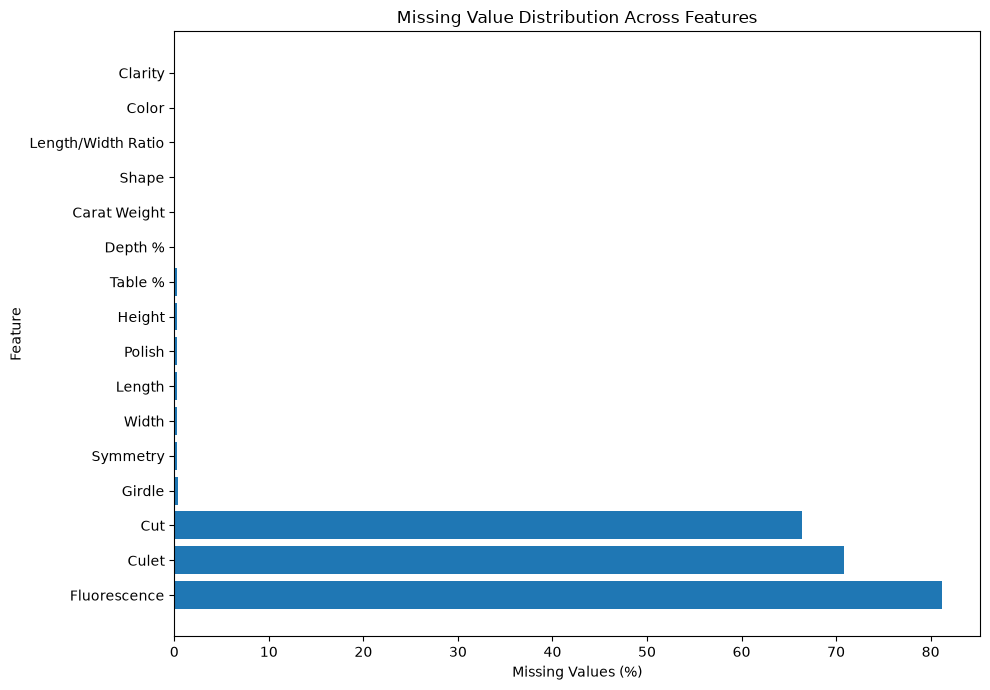

In [6]:
plt.figure(figsize=(10, 7))

plt.barh(
    missing_summary.index,
    missing_summary["Missing Percentage"]
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.title("Missing Value Distribution Across Features")

plt.tight_layout()
plt.show()

In [7]:
missing_by_type = df.groupby("Type")[[
    "Cut", "Culet", "Fluorescence"
]].apply(lambda x: x.isna().mean() * 100)

missing_by_type

,Cut,Culet,Fluorescence
Type,,,
GIA,71.058122,99.105812,63.606557
GIA Lab-Grown,43.814844,100.000000,100.000000
IGI Lab-Grown,73.052295,0.800427,100.000000


In [8]:
numerical_summary = df.describe().T

numerical_summary

,count,mean,std,min,25%,50%,75%,max
Carat Weight,6477.0,1.235394,0.506246,1.00,1.01,1.03,1.1900,9.38
Length/Width Ratio,6477.0,1.329683,0.325719,1.00,1.02,1.27,1.5100,2.58
Depth %,6475.0,64.208463,4.773125,46.10,61.20,63.10,67.6000,77.00
Table %,6465.0,61.830317,4.760197,51.00,58.00,61.00,65.0000,78.00
Length,6462.0,7.663448,1.674960,5.18,6.33,7.42,8.6575,15.21
Width,6462.0,6.097283,1.150103,4.42,5.39,5.64,6.5975,14.88
Height,6462.0,3.885206,0.599005,2.67,3.46,3.67,4.1000,8.17
Price,6482.0,3529.458963,3280.858597,1010.00,1210.00,3320.00,4390.0000,39460.00


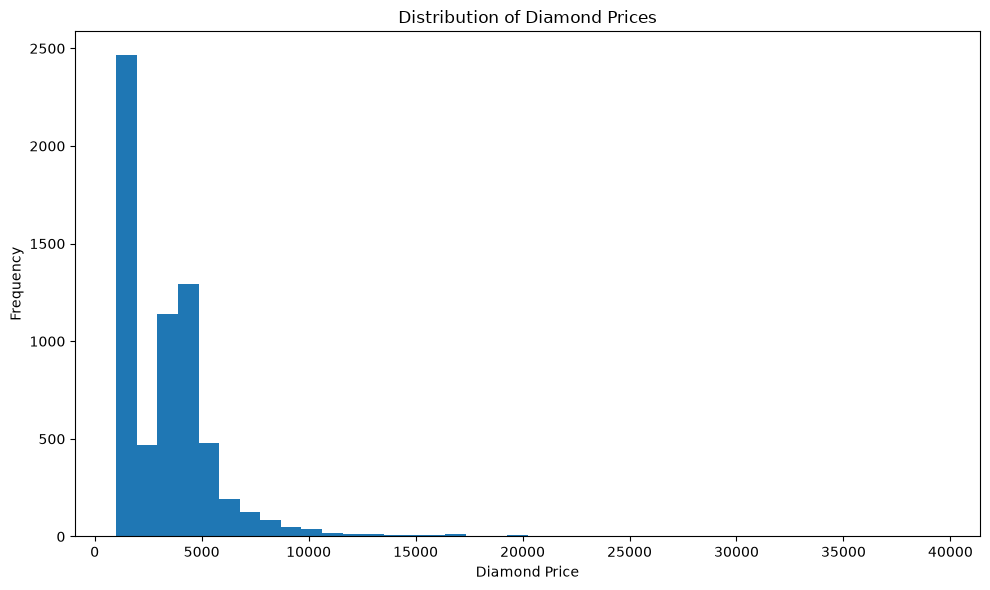

In [9]:
plt.figure(figsize=(10, 6))

plt.hist(df["Price"], bins=40)

plt.xlabel("Diamond Price")
plt.ylabel("Frequency")
plt.title("Distribution of Diamond Prices")

plt.tight_layout()
plt.show()

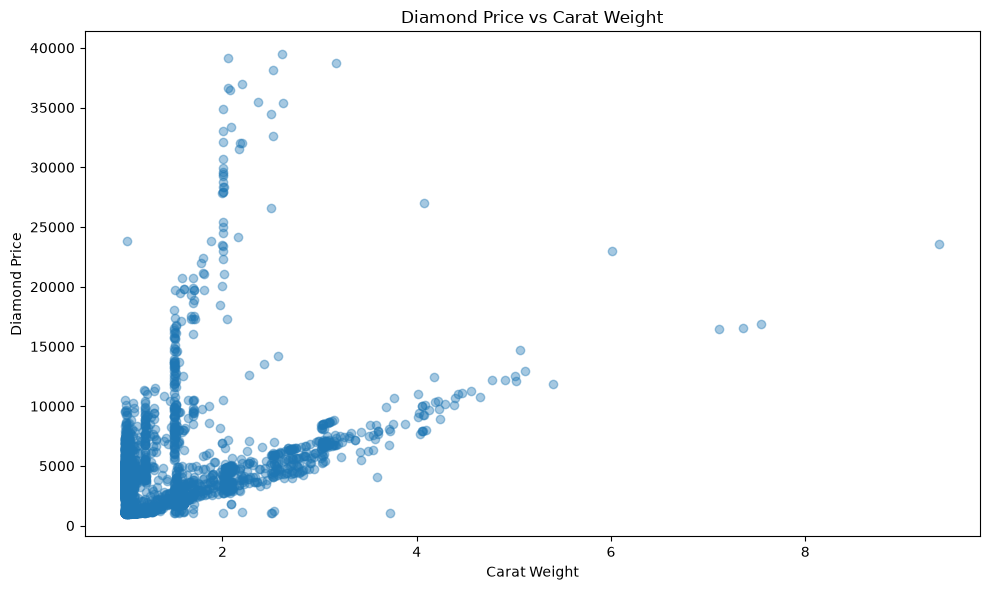

In [10]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Carat Weight"],
    df["Price"],
    alpha=0.4
)

plt.xlabel("Carat Weight")
plt.ylabel("Diamond Price")
plt.title("Diamond Price vs Carat Weight")

plt.tight_layout()
plt.show()

In [11]:
correlation_with_price = (
    df.select_dtypes(include=np.number)
      .corr()["Price"]
      .sort_values(ascending=False)
)

correlation_with_price

Price                 1.000000
Carat Weight          0.368770
Length                0.314793
Width                 0.261288
Height                0.217991
Length/Width Ratio    0.151801
Table %              -0.098497
Depth %              -0.183515
Name: Price, dtype: float64

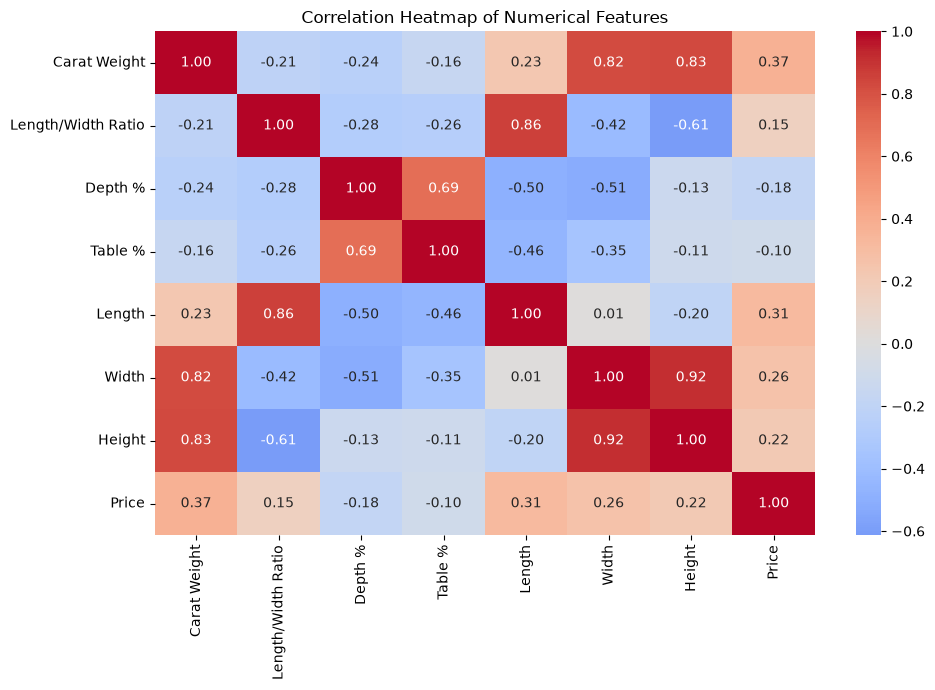

In [12]:
numerical_data = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numerical_data.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [13]:
type_summary = (
    df.groupby("Type")["Price"]
      .agg(["count", "mean", "median"])
      .sort_values("mean", ascending=False)
)

type_summary

,count,mean,median
Type,,,
GIA,3355,4890.969598,4090.0
GIA Lab-Grown,1253,2702.913009,1790.0
IGI Lab-Grown,1874,1644.610459,1150.0


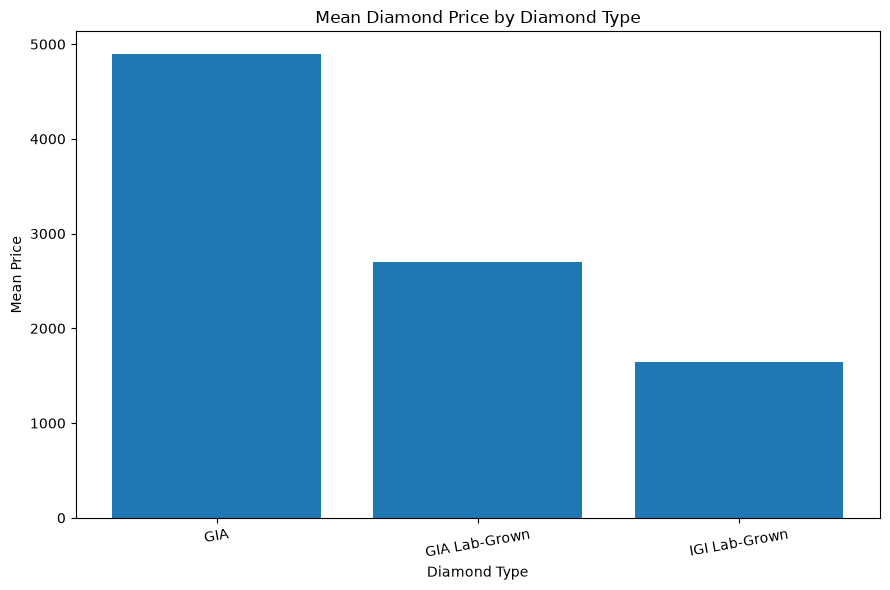

In [14]:
plt.figure(figsize=(9, 6))

plt.bar(
    type_summary.index,
    type_summary["mean"]
)

plt.xlabel("Diamond Type")
plt.ylabel("Mean Price")
plt.title("Mean Diamond Price by Diamond Type")

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

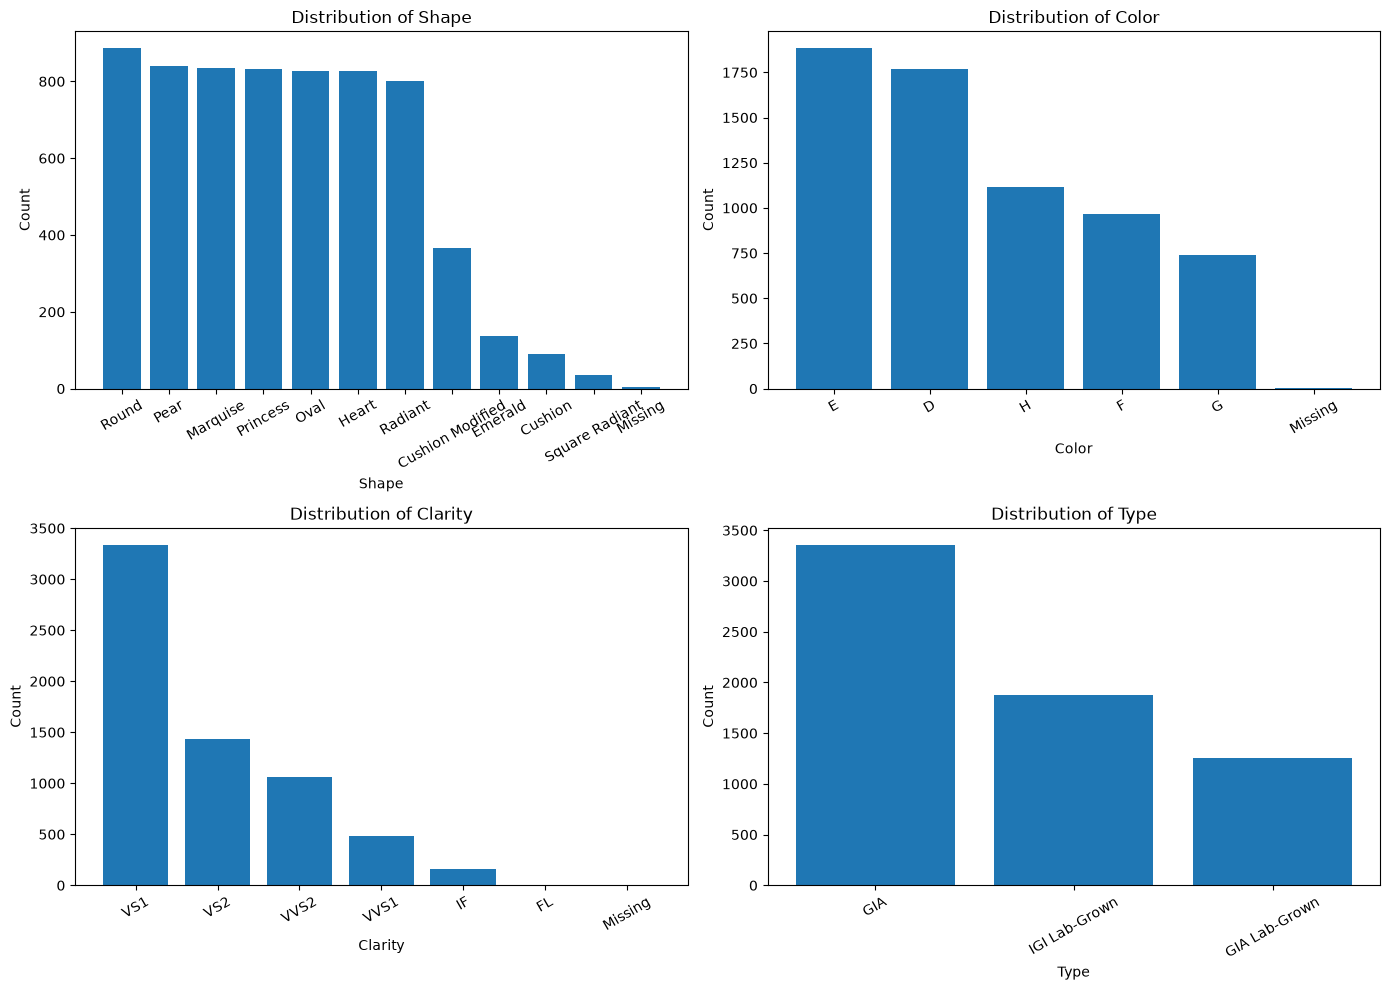

In [15]:
features_to_plot = ["Shape", "Color", "Clarity", "Type"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, feature in zip(axes.flatten(), features_to_plot):
    counts = df[feature].fillna("Missing").value_counts()

    labels = [str(x) for x in counts.index]
    values = counts.values

    ax.bar(labels, values)
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## EDA Summary

The exploratory data analysis produced the following observations:

- Diamond prices show a strong right-skewed distribution with a long upper-price tail.
- Carat Weight has the strongest numerical correlation with Price, followed by Length, Width, and Height.
- Price generally increases with Carat Weight, but substantial variation exists at similar carat values.
- Several dimensional features contain overlapping information, particularly Width and Height.
- Diamond Type shows substantial differences in the observed price distributions.
- Fluorescence, Culet, and Cut contain high proportions of missing values, and their missingness varies across diamond types.
- Categorical features such as Shape, Color, Clarity, and Type have different levels of representation in the dataset.
- These observations motivate the use of multiple features, systematic feature ablation, robust validation, and explainable machine-learning models.

In [16]:
from sklearn.model_selection import train_test_split

X = df.drop("Price", axis=1)
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (5185, 17)
Testing data shape: (1297, 17)
Training target shape: (5185,)
Testing target shape: (1297,)


In [17]:
categorical_features = [
    "Shape",
    "Cut",
    "Color",
    "Clarity",
    "Polish",
    "Symmetry",
    "Girdle",
    "Culet",
    "Type",
    "Fluorescence"
]

numerical_features = [
    "Carat Weight",
    "Length/Width Ratio",
    "Depth %",
    "Table %",
    "Length",
    "Width",
    "Height"
]

print("Number of categorical features:", len(categorical_features))
print("Number of numerical features:", len(numerical_features))

Number of categorical features: 10
Number of numerical features: 7


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [19]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)
print("Testing processed shape:", X_test_processed.shape)

Training processed shape: (5185, 88)
Testing processed shape: (1297, 88)


In [20]:
if hasattr(X_train_processed, "toarray"):
    X_train_check = X_train_processed.toarray()
else:
    X_train_check = X_train_processed

if hasattr(X_test_processed, "toarray"):
    X_test_check = X_test_processed.toarray()
else:
    X_test_check = X_test_processed

print(
    "Missing values in processed training data:",
    np.isnan(X_train_check).sum()
)

print(
    "Missing values in processed testing data:",
    np.isnan(X_test_check).sum()
)

print("Training processed shape:", X_train_check.shape)
print("Testing processed shape:", X_test_check.shape)

Missing values in processed training data: 0
Missing values in processed testing data: 0
Training processed shape: (5185, 88)
Testing processed shape: (1297, 88)


In [21]:
# Feature groups for the ablation study

features_4c = [
    "Carat Weight",
    "Cut",
    "Color",
    "Clarity"
]

features_dimensions = [
    "Length/Width Ratio",
    "Depth %",
    "Table %",
    "Length",
    "Width",
    "Height"
]

features_physical_quality = [
    "Shape",
    "Polish",
    "Symmetry",
    "Girdle",
    "Culet",
    "Fluorescence",
    "Type"
]

print("4C features:", len(features_4c))
print("Dimension features:", len(features_dimensions))
print("Physical/quality features:", len(features_physical_quality))

4C features: 4
Dimension features: 6
Physical/quality features: 7


In [22]:
ablation_feature_sets = {
    "4C Features": features_4c,
    "4C + Dimensions": features_4c + features_dimensions,
    "4C + Dimensions + Physical/Quality": (
        features_4c + features_dimensions + features_physical_quality
    )
}

for name, features in ablation_feature_sets.items():
    print(f"{name}: {len(features)} features")

4C Features: 4 features
4C + Dimensions: 10 features
4C + Dimensions + Physical/Quality: 17 features


In [23]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ablation_results = []

for name, features in ablation_feature_sets.items():

    X_train_subset = X_train[features]
    X_test_subset = X_test[features]

    categorical_subset = [
        feature for feature in categorical_features
        if feature in features
    ]

    numerical_subset = [
        feature for feature in numerical_features
        if feature in features
    ]

    subset_preprocessor = ColumnTransformer([
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numerical_subset
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="constant",
                    fill_value="Unknown"
                )),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_subset
        )
    ])

    X_train_subset_processed = subset_preprocessor.fit_transform(
        X_train_subset
    )

    X_test_subset_processed = subset_preprocessor.transform(
        X_test_subset
    )

    model = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_subset_processed, y_train)

    predictions = model.predict(X_test_subset_processed)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    ablation_results.append({
        "Experiment": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

ablation_results_df = pd.DataFrame(ablation_results)

ablation_results_df

,Experiment,MAE,RMSE,R2
0,4C Features,951.624187,2315.877319,0.474177
1,4C + Dimensions,596.246419,1341.302885,0.823615
2,4C + Dimensions + Physical/Quality,391.103845,1118.074804,0.877440


In [24]:
baseline_r2 = ablation_results_df.loc[
    ablation_results_df["Experiment"] == "4C Features", "R2"
].iloc[0]

baseline_mae = ablation_results_df.loc[
    ablation_results_df["Experiment"] == "4C Features", "MAE"
].iloc[0]

final_r2 = ablation_results_df.loc[
    ablation_results_df["Experiment"] == "4C + Dimensions + Physical/Quality", "R2"
].iloc[0]

final_mae = ablation_results_df.loc[
    ablation_results_df["Experiment"] == "4C + Dimensions + Physical/Quality", "MAE"
].iloc[0]

r2_improvement = ((final_r2 - baseline_r2) / baseline_r2) * 100
mae_reduction = ((baseline_mae - final_mae) / baseline_mae) * 100

print(f"R² improvement from 4C to 17 features: {r2_improvement:.2f}%")
print(f"MAE reduction from 4C to 17 features: {mae_reduction:.2f}%")

R² improvement from 4C to 17 features: 85.04%
MAE reduction from 4C to 17 features: 58.90%


In [25]:
ablation_results_df = ablation_results_df.round(4)

print("Ablation Study Results")
display(ablation_results_df)

Ablation Study Results


,Experiment,MAE,RMSE,R2
0,4C Features,951.6242,2315.8773,0.4742
1,4C + Dimensions,596.2464,1341.3029,0.8236
2,4C + Dimensions + Physical/Quality,391.1038,1118.0748,0.8774


In [26]:
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

print("Models defined:")
for model_name in models:
    print("-", model_name)

Models defined:
- Random Forest
- Gradient Boosting
- Extra Trees


In [27]:
model_results = []

for model_name, model in models.items():

    model.fit(X_train_processed, y_train)

    predictions = model.predict(X_test_processed)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    model_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

model_results_df = pd.DataFrame(model_results)

model_results_df

,Model,MAE,RMSE,R2
0,Random Forest,391.103845,1118.074804,0.877440
1,Gradient Boosting,435.579727,1188.664989,0.861475
2,Extra Trees,405.625998,1242.791826,0.848572


In [28]:
model_results_df = model_results_df.round(4)

print("Model Comparison Results")
display(model_results_df)

Model Comparison Results


,Model,MAE,RMSE,R2
0,Random Forest,391.1038,1118.0748,0.8774
1,Gradient Boosting,435.5797,1188.6650,0.8615
2,Extra Trees,405.6260,1242.7918,0.8486


In [29]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

cv_scores = cross_validate(
    rf_model,
    X_train_processed,
    y_train,
    cv=cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=-1
)

cv_mae = -cv_scores["test_MAE"]
cv_rmse = -cv_scores["test_RMSE"]
cv_r2 = cv_scores["test_R2"]

print("5-Fold Cross-Validation Results")
print("--------------------------------")
print(f"MAE  : {cv_mae.mean():.4f} ± {cv_mae.std():.4f}")
print(f"RMSE : {cv_rmse.mean():.4f} ± {cv_rmse.std():.4f}")
print(f"R²   : {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")

print("\nFold-wise R²:")
print(np.round(cv_r2, 4))

5-Fold Cross-Validation Results
--------------------------------
MAE  : 443.3971 ± 49.7413
RMSE : 1352.1692 ± 249.9426
R²   : 0.8195 ± 0.0756

Fold-wise R²:
[0.8339 0.8997 0.7283 0.9002 0.7354]


In [30]:
cv_results_df = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "R2": cv_r2,
    "MAE": cv_mae,
    "RMSE": cv_rmse
})

cv_results_df = cv_results_df.round(4)

display(cv_results_df)

print("\nMean ± Standard Deviation")
print(f"R²   : {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")
print(f"MAE  : {cv_mae.mean():.4f} ± {cv_mae.std():.4f}")
print(f"RMSE : {cv_rmse.mean():.4f} ± {cv_rmse.std():.4f}")

,Fold,R2,MAE,RMSE
0,1,0.8339,471.5901,1406.4271
1,2,0.8997,420.1656,1164.5915
2,3,0.7283,431.5428,1508.2385
3,4,0.9002,373.1137,987.5162
4,5,0.7354,520.5733,1694.0725



Mean ± Standard Deviation
R²   : 0.8195 ± 0.0756
MAE  : 443.3971 ± 49.7413
RMSE : 1352.1692 ± 249.9426


In [31]:
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))
print("\nFirst 20 processed feature names:")
print(feature_names[:20])

Number of processed features: 88

First 20 processed feature names:
['num__Carat Weight' 'num__Length/Width Ratio' 'num__Depth %'
 'num__Table %' 'num__Length' 'num__Width' 'num__Height'
 'cat__Shape_Cushion' 'cat__Shape_Cushion Modified' 'cat__Shape_Emerald'
 'cat__Shape_Heart' 'cat__Shape_Marquise' 'cat__Shape_Oval'
 'cat__Shape_Pear' 'cat__Shape_Princess' 'cat__Shape_Radiant'
 'cat__Shape_Round' 'cat__Shape_Square Radiant' 'cat__Shape_Unknown'
 'cat__Cut_Astor']


In [32]:
import shap

print("SHAP version:", shap.__version__)

# Use the trained Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

# Use a small sample for SHAP analysis
X_shap = X_test_check[:200]

explainer = shap.TreeExplainer(rf_model)

print("SHAP explainer created successfully!")
print("SHAP sample size:", X_shap.shape)

SHAP version: 0.52.0
SHAP explainer created successfully!
SHAP sample size: (200, 88)


In [33]:
shap_values = explainer.shap_values(X_shap)

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (200, 88)


In [34]:
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": np.abs(shap_values).mean(axis=0)
})

shap_importance = (
    shap_importance
    .sort_values("Mean Absolute SHAP", ascending=False)
    .reset_index(drop=True)
)

shap_importance.head(15)

,Feature,Mean Absolute SHAP
0,cat__Type_GIA,1517.823592
1,num__Carat Weight,789.503944
2,num__Length,373.409162
3,num__Width,225.939150
4,cat__Shape_Marquise,181.007498
5,cat__Color_D,105.945877
6,cat__Color_H,100.002372
7,num__Depth %,87.157289
8,cat__Clarity_VS2,77.617395
9,cat__Clarity_VS1,48.418506


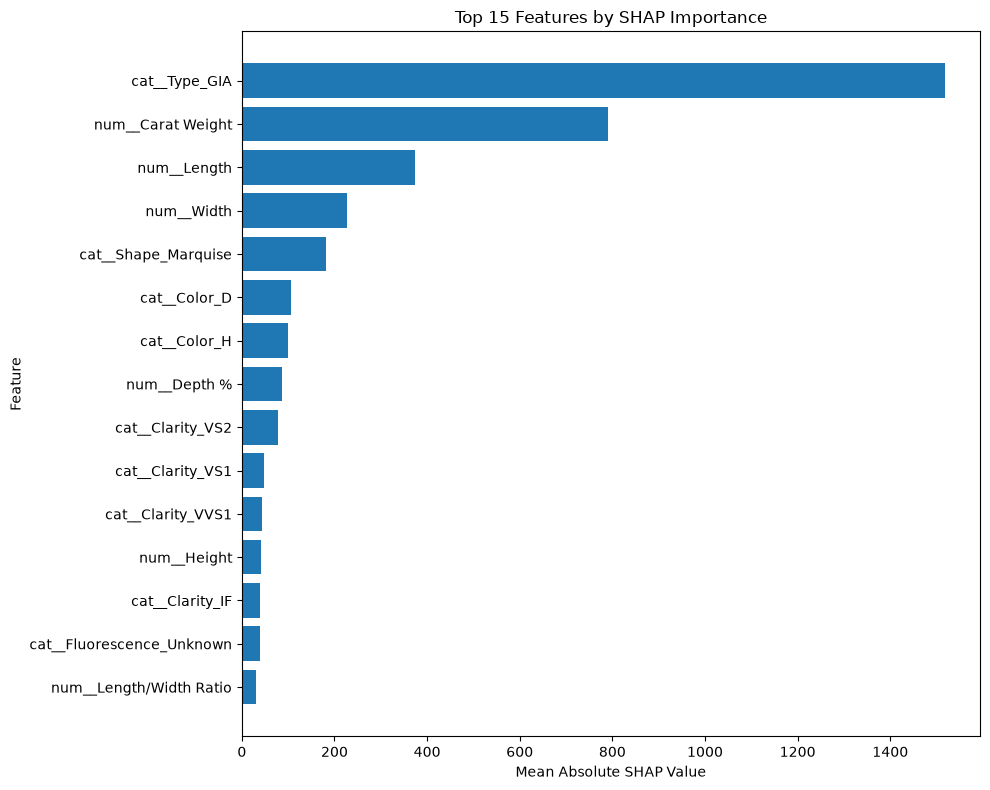

In [35]:
top_shap = shap_importance.head(15).sort_values(
    "Mean Absolute SHAP",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_shap["Feature"],
    top_shap["Mean Absolute SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top 15 Features by SHAP Importance")

plt.tight_layout()
plt.show()

In [36]:
# Select one test diamond
sample_index = 0

sample_diamond = X_test.iloc[[sample_index]].copy()
actual_price = y_test.iloc[sample_index]

print("Selected Diamond:")
display(sample_diamond)

print(f"Actual Price: {actual_price}")

Selected Diamond:


,Shape,Cut,Color,Clarity,Carat Weight,Length/Width Ratio,Depth %,Table %,Polish,Symmetry,Girdle,Culet,Length,Width,Height,Type,Fluorescence
3558,Pear,NaN,D,VS2,1.01,1.53,64.2,56.0,Excellent,Excellent,Thick to Very Thick,NaN,8.36,5.48,3.52,GIA,NaN


Actual Price: 4390


In [37]:
# Preprocess the selected diamond
sample_processed = preprocessor.transform(sample_diamond)

# Predict price
predicted_price = rf_model.predict(sample_processed)[0]

absolute_error = abs(actual_price - predicted_price)

print(f"Actual Price: ₹{actual_price:,.2f}")
print(f"Predicted Price: ₹{predicted_price:,.2f}")
print(f"Absolute Error: ₹{absolute_error:,.2f}")

Actual Price: ₹4,390.00
Predicted Price: ₹4,601.44
Absolute Error: ₹211.44


In [38]:
# Create a What-If scenario by changing only Carat Weight
carat_scenario = sample_diamond.copy()

carat_scenario["Carat Weight"] = 1.50

# Preprocess and predict
carat_processed = preprocessor.transform(carat_scenario)
carat_prediction = rf_model.predict(carat_processed)[0]

carat_change = carat_prediction - predicted_price

print(f"Original Carat Weight: {sample_diamond['Carat Weight'].iloc[0]:.2f}")
print(f"What-If Carat Weight: 1.50")
print(f"Original Prediction: ₹{predicted_price:,.2f}")
print(f"What-If Prediction: ₹{carat_prediction:,.2f}")
print(f"Predicted Price Change: ₹{carat_change:,.2f}")

Original Carat Weight: 1.01
What-If Carat Weight: 1.50
Original Prediction: ₹4,601.44
What-If Prediction: ₹9,299.76
Predicted Price Change: ₹4,698.32


In [39]:
# Create a What-If scenario by changing only Color
color_scenario = sample_diamond.copy()

color_scenario["Color"] = "H"

# Preprocess and predict
color_processed = preprocessor.transform(color_scenario)
color_prediction = rf_model.predict(color_processed)[0]

color_change = color_prediction - predicted_price

print(f"Original Color: {sample_diamond['Color'].iloc[0]}")
print(f"What-If Color: H")
print(f"Original Prediction: ₹{predicted_price:,.2f}")
print(f"What-If Prediction: ₹{color_prediction:,.2f}")
print(f"Predicted Price Change: ₹{color_change:,.2f}")

Original Color: D
What-If Color: H
Original Prediction: ₹4,601.44
What-If Prediction: ₹3,685.10
Predicted Price Change: ₹-916.34


In [40]:
what_if_results = pd.DataFrame({
    "Scenario": [
        "Original Diamond",
        "Carat Weight: 1.50",
        "Color: H"
    ],
    "Changed Feature": [
        "None",
        "Carat Weight",
        "Color"
    ],
    "Predicted Price": [
        predicted_price,
        carat_prediction,
        color_prediction
    ]
})

what_if_results["Predicted Price"] = (
    what_if_results["Predicted Price"].round(2)
)

display(what_if_results)

,Scenario,Changed Feature,Predicted Price
0,Original Diamond,None,4601.44
1,Carat Weight: 1.50,Carat Weight,9299.76
2,Color: H,Color,3685.10


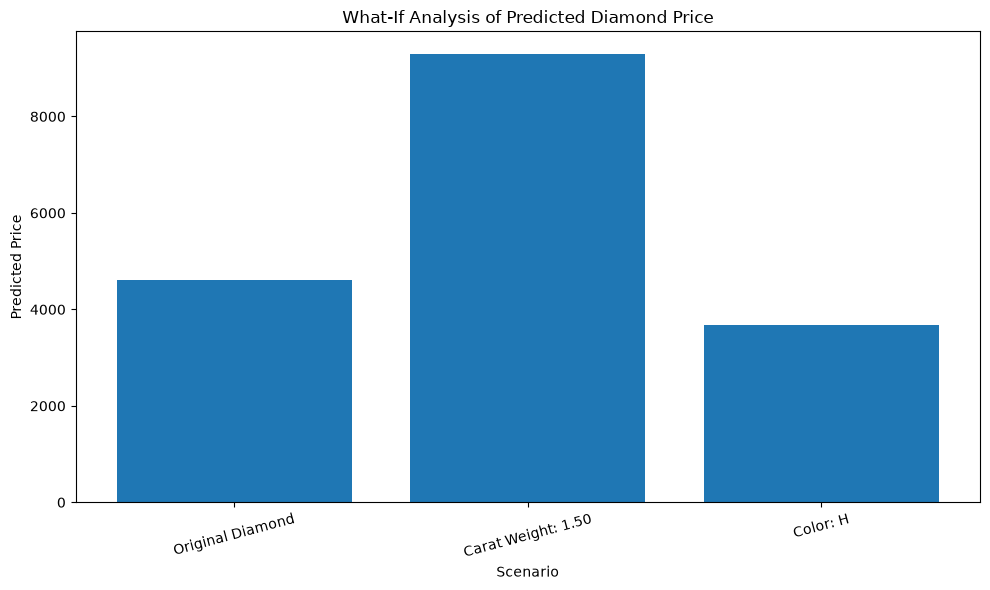

In [41]:
plt.figure(figsize=(10, 6))

plt.bar(
    what_if_results["Scenario"],
    what_if_results["Predicted Price"]
)

plt.xlabel("Scenario")
plt.ylabel("Predicted Price")
plt.title("What-If Analysis of Predicted Diamond Price")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Final Results Summary

The experimental results demonstrate that enriching the feature set substantially improves diamond price prediction performance.

### Feature Ablation Results

The Random Forest model was evaluated using three progressively richer feature sets:

| Feature Set | MAE | RMSE | R² |
|---|---:|---:|---:|
| 4C Features | 951.62 | 2315.88 | 0.4742 |
| 4C + Dimensions | 596.25 | 1341.30 | 0.8236 |
| All 17 Features | 391.10 | 1118.07 | 0.8774 |

Moving from the traditional 4C feature set to the complete 17-feature representation reduced MAE by approximately 58.90% and increased R² from 0.4742 to 0.8774.

### Model Comparison

Using the complete feature set, three regression models were evaluated:

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Random Forest | 391.10 | 1118.07 | 0.8774 |
| Gradient Boosting | 435.58 | 1188.66 | 0.8615 |
| Extra Trees | 405.63 | 1242.79 | 0.8486 |

On the held-out test set, Random Forest achieved the highest R² and the lowest MAE and RMSE among the three evaluated models.

### Cross-Validation

Five-fold cross-validation of the Random Forest model produced:

- Mean R²: **0.8195 ± 0.0756**
- Mean MAE: **443.40 ± 49.74**
- Mean RMSE: **1352.17 ± 249.94**

The variation across folds indicates that model performance differs across different subsets of the training data.

### Explainability

SHAP analysis identified `Type_GIA`, Carat Weight, Length, and Width among the most influential processed features in the sampled predictions.

SHAP values represent the contribution of features to model predictions and should not be interpreted as causal effects.

### What-If Analysis

The What-If experiment demonstrated that changing individual diamond characteristics can substantially change the model's predicted price.

For the selected diamond:

- Original prediction: **₹4,601.44**
- Carat Weight changed from 1.01 to 1.50: **₹9,299.76**
- Color changed from D to H: **₹3,685.10**

These results demonstrate how the model can be used for interactive sensitivity analysis. The What-If results represent model-based scenarios rather than guaranteed market prices or causal effects.

## Research Findings

The experimental study provides the following research findings:

1. **Feature enrichment improves prediction performance.**  
   The ablation study shows a substantial improvement when moving from the traditional 4C features to a richer set of 17 diamond characteristics.

2. **Dimensional characteristics provide significant predictive information.**  
   Adding Length, Width, Height, Depth %, Table %, and Length/Width Ratio increased the R² from 0.4742 to 0.8236.

3. **Additional physical and quality characteristics provide further improvement.**  
   Adding Shape, Polish, Symmetry, Girdle, Culet, Fluorescence, and Type increased the test-set R² from 0.8236 to 0.8774.

4. **Random Forest performed strongly in the evaluated test-set comparison.**  
   Among Random Forest, Gradient Boosting, and Extra Trees, Random Forest achieved the lowest MAE and RMSE and the highest R² on the held-out test set.

5. **Cross-validation shows variation in model performance.**  
   The five-fold cross-validation produced an average R² of 0.8195 with a standard deviation of 0.0756. This indicates that performance can vary depending on the data partition.

6. **Model predictions can be explained using SHAP.**  
   SHAP analysis identified Type_GIA, Carat Weight, Length, and Width among the most influential processed features in the sampled predictions.

7. **What-If analysis provides an interactive interpretation mechanism.**  
   Controlled changes to individual diamond characteristics produced noticeable changes in predicted price, demonstrating how the trained model can be used for sensitivity analysis.

8. **Prediction should not be interpreted as causation.**  
   The observed feature contributions and What-If changes describe the behavior of the trained model on the available dataset. They do not establish causal relationships or guarantee actual market prices.

## Limitations

Although the proposed framework provides encouraging results, several limitations should be considered:

1. **Dataset scope:**  
   The study uses a dataset containing 6,482 unique records after duplicate removal. The dataset may not fully represent the diversity of the global diamond market.

2. **Single dataset source:**  
   The experiments are based on one diamond marketplace dataset. Therefore, the results should not automatically be generalized to other retailers, regions, or market conditions.

3. **Missing values:**  
   Some features, particularly Fluorescence, Culet, and Cut, contain substantial missing values. Missing categorical values were represented as "Unknown", which preserves the missingness information but may still affect model behavior.

4. **Market and temporal information:**  
   The dataset does not provide a complete time-series framework for tracking price changes over time. Therefore, this study does not claim to predict future market prices.

5. **Model scope:**  
   The main experiments evaluate Random Forest, Gradient Boosting, and Extra Trees. Other advanced approaches, including deep-learning and specialized boosting methods, were not comprehensively evaluated.

6. **Interpretability limitation:**  
   SHAP explains how features contribute to the predictions of the trained model. These contributions should not be interpreted as causal relationships.

7. **What-If limitation:**  
   What-If analysis demonstrates model sensitivity to controlled feature changes. The resulting prices are model estimates and should not be interpreted as guaranteed real-world market prices.

8. **External validation:**  
   The current study uses an internal train-test split and cross-validation. Evaluation on an independent external diamond dataset would provide stronger evidence of generalization.

These limitations define important directions for extending the study in future research.

## Future Work

The current study can be extended in several directions:

1. **External dataset validation:**  
   The proposed framework can be evaluated on independent diamond datasets from different retailers, regions, or marketplaces to examine its generalization capability.

2. **Larger and more diverse datasets:**  
   Future studies can incorporate larger datasets containing a wider range of diamond characteristics and market segments.

3. **Real-time market data:**  
   A time-stamped dataset could be used to study changes in diamond prices over time and investigate market trends.

4. **Advanced machine-learning models:**  
   Future work can evaluate additional boosting methods, deep-learning models, and ensemble approaches to determine whether they provide further improvements.

5. **Uncertainty estimation:**  
   Future versions can provide prediction intervals or uncertainty estimates along with the predicted price instead of reporting only a single point estimate.

6. **Advanced explainability:**  
   Future research can investigate additional explainability techniques and compare their consistency with SHAP-based explanations.

7. **Interactive prediction system:**  
   The framework can be developed into a web-based application where users can enter diamond characteristics, obtain a predicted price, view feature explanations, and perform What-If analysis interactively.

8. **Additional diamond characteristics:**  
   If reliable data are available, features such as fluorescence grade, symmetry, polish, certification information, and other gemological characteristics can be investigated further.

9. **Model monitoring and updating:**  
   With continuously collected market data, future systems could be periodically retrained to account for changes in observed pricing patterns.

10. **Broader validation of What-If analysis:**  
    Future work can evaluate What-If scenarios across many diamonds rather than a single selected example to determine whether the observed sensitivity patterns remain consistent.

## Conclusion

This study developed an explainable and robust machine-learning framework for diamond price prediction using a richer set of diamond characteristics.

The feature ablation experiments demonstrated that expanding the input representation beyond traditional 4C characteristics substantially improved prediction performance. The R² increased from **0.4742** using the 4C feature set to **0.8774** using the complete 17-feature representation, while MAE decreased from **951.62** to **391.10** on the held-out test set.

Among the evaluated models, Random Forest achieved the strongest performance on the held-out test set, with an R² of **0.8774**, MAE of **391.10**, and RMSE of **1118.07**. Five-fold cross-validation produced a mean R² of **0.8195 ± 0.0756**, providing an additional assessment of model performance across different data partitions.

The study also incorporated SHAP-based explainability to examine the contribution of individual processed features to model predictions. Furthermore, controlled What-If analysis demonstrated how changing selected diamond characteristics can alter the model's estimated price.

Overall, the results show that combining feature enrichment, systematic ablation, model comparison, cross-validation, explainability, and What-If analysis provides a more comprehensive approach to diamond price prediction than evaluating prediction accuracy alone.

However, the findings are limited to the available dataset and experimental setup. External validation using independent datasets and additional market information would be required to establish broader generalization.

The proposed framework therefore provides a foundation for developing more transparent, interactive, and practically useful diamond price prediction systems.

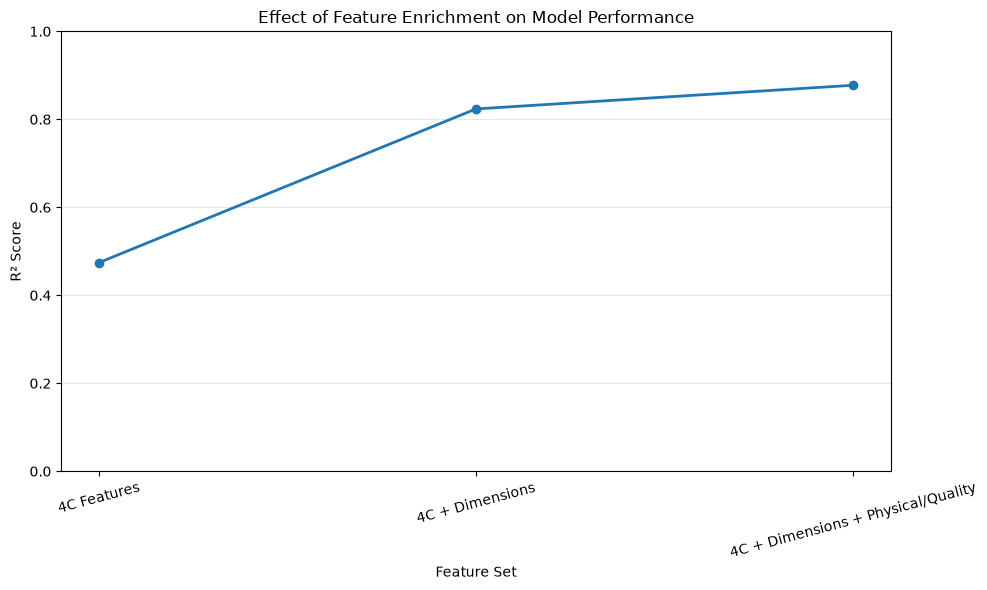

In [43]:
plt.figure(figsize=(10, 6))

plt.plot(
    ablation_results_df["Experiment"],
    ablation_results_df["R2"],
    marker="o",
    linewidth=2
)

plt.xlabel("Feature Set")
plt.ylabel("R² Score")
plt.title("Effect of Feature Enrichment on Model Performance")

plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

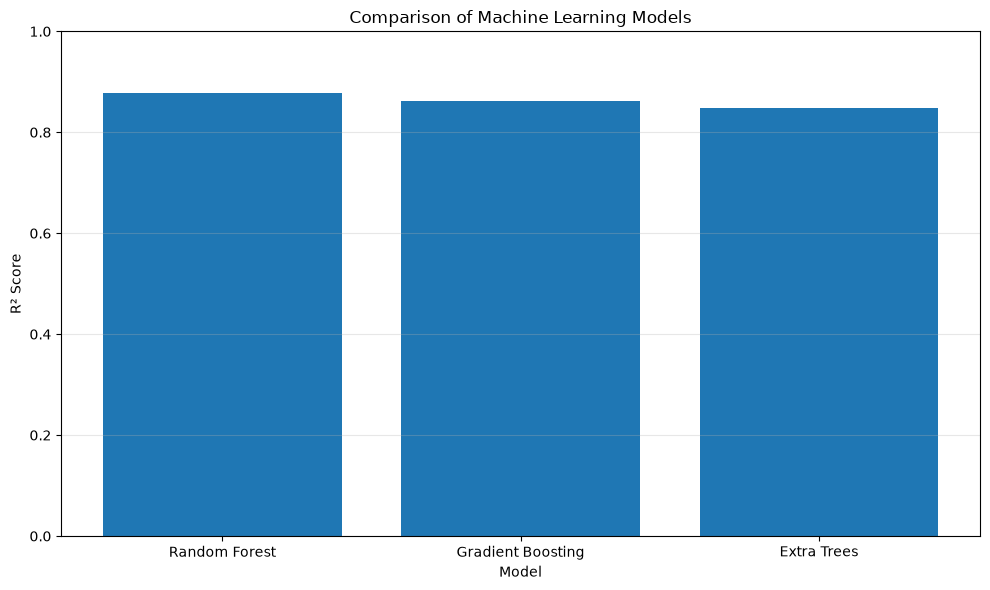

In [44]:
plt.figure(figsize=(10, 6))

plt.bar(
    model_results_df["Model"],
    model_results_df["R2"]
)

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("Comparison of Machine Learning Models")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

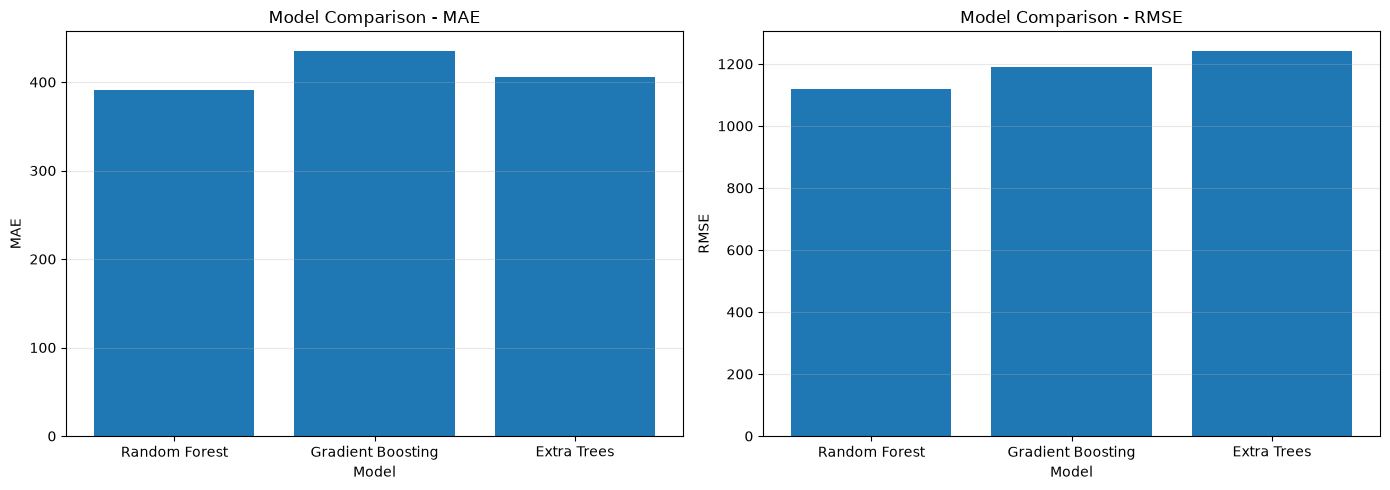

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# MAE
axes[0].bar(
    model_results_df["Model"],
    model_results_df["MAE"]
)

axes[0].set_title("Model Comparison - MAE")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("MAE")
axes[0].grid(axis="y", alpha=0.3)

# RMSE
axes[1].bar(
    model_results_df["Model"],
    model_results_df["RMSE"]
)

axes[1].set_title("Model Comparison - RMSE")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("RMSE")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

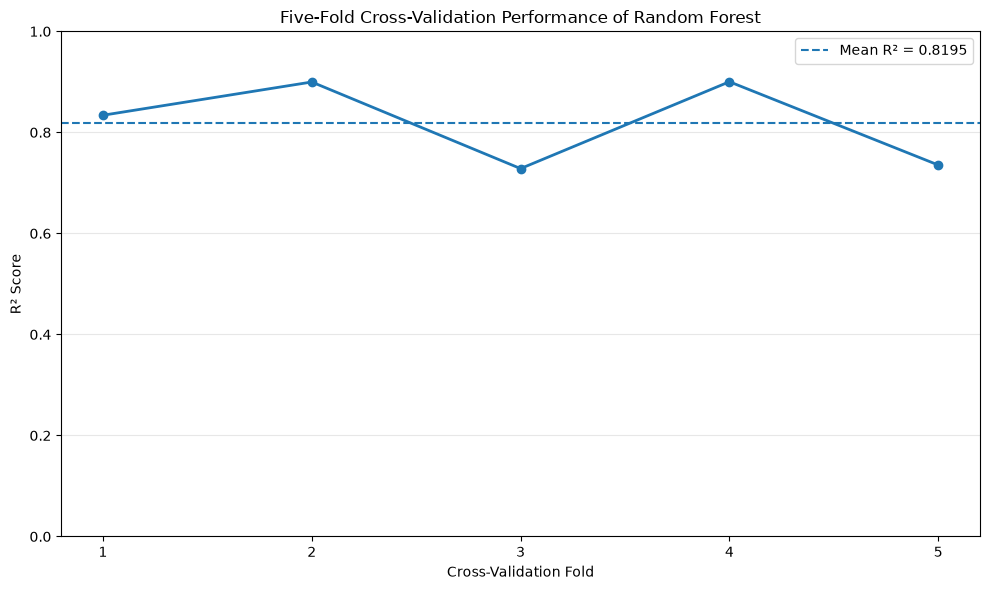

In [46]:
plt.figure(figsize=(10, 6))

plt.plot(
    cv_results_df["Fold"],
    cv_results_df["R2"],
    marker="o",
    linewidth=2
)

plt.axhline(
    cv_r2.mean(),
    linestyle="--",
    label=f"Mean R² = {cv_r2.mean():.4f}"
)

plt.xlabel("Cross-Validation Fold")
plt.ylabel("R² Score")
plt.title("Five-Fold Cross-Validation Performance of Random Forest")

plt.xticks(cv_results_df["Fold"])
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

## Final Experimental Results

### Feature Ablation

The feature ablation experiment shows that progressively enriching the feature set improves prediction performance.

- 4C Features: R² = 0.4742
- 4C + Dimensions: R² = 0.8236
- All 17 Features: R² = 0.8774

The complete feature representation achieved a substantial improvement over the traditional 4C baseline.

### Model Comparison

On the held-out test set:

- Random Forest: R² = 0.8774, MAE = 391.10, RMSE = 1118.07
- Gradient Boosting: R² = 0.8615, MAE = 435.58, RMSE = 1188.66
- Extra Trees: R² = 0.8486, MAE = 405.63, RMSE = 1242.79

### Cross-Validation

Five-fold cross-validation of the Random Forest model produced a mean R² of 0.8195 with a standard deviation of 0.0756.

The fold-wise results demonstrate variation in predictive performance across different training-validation partitions.

## References

The following studies were reviewed to identify recurring limitations and research opportunities in diamond price prediction:

1. Xiao, M. (2024). *Diamond Price Prediction Based on Regression Algorithms: Analyzing Key Factors and Model Performance.*

2. Kigo, J., Omondi, J., & Omolo, J. (2023). *Assessing Predictive Performance of Supervised Machine Learning Algorithms for a Diamond Pricing Model.*

3. Madena, K., & Pandey, S. *Exploring Predictive Insights for Diamond Price along with Practical Approach through Machine Learning Model.*

4. Zhang, B. (2025). *Enhancing Diamond Price Prediction with Feature Optimization and Interaction Terms in Machine Learning.*

5. Kamila, A. R., et al. (2024). *Analysis Comparison of K-Nearest Neighbor, Multi-Layer Perceptron, and Decision Tree Algorithms in Diamond Price Prediction.*

6. Amadavadi, K., Rane, R., & Patankar, R. (2024). *Diamond Price Prediction using Machine Learning Techniques.*

7. Ranglani, H. (2025). *Integrating Machine Learning for Diamond Price Prediction and Distinguishing Natural Diamonds from Lab Grown: A Unified Approach.*

8. Randhawa, A. K., et al. (2025). *Predicting Diamond Prices Using Regression in Machine Learning.*

9. Xu, J. (2024). *Prediction on the Prices of Laboratory-Grown Diamonds based on Multiple Linear Regression Model.*

10. Acharya, K. N., & Senapati, M. R. (2024). *Diamond Price Prediction Using Data Mining Techniques.*

These studies were used to identify limitations related to feature coverage, dataset scope, model comparison, generalization, explainability, and practical interaction. The present study builds upon these observations through feature ablation, robust validation, SHAP-based explainability, and controlled What-If analysis.

In [48]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

models_6 = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "KNN": KNeighborsRegressor(
        n_neighbors=5
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

print("6 models defined successfully!")

for name in models_6:
    print("-", name)

6 models defined successfully!
- Linear Regression
- Decision Tree
- KNN
- Random Forest
- Gradient Boosting
- XGBoost


In [49]:
model_results_6 = []

for model_name, model in models_6.items():

    model.fit(X_train_processed, y_train)

    predictions = model.predict(X_test_processed)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    model_results_6.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

model_results_6_df = pd.DataFrame(model_results_6)

model_results_6_df

,Model,MAE,RMSE,R2
0,Linear Regression,972.040718,1774.015826,0.691452
1,Decision Tree,505.494988,1303.098008,0.833520
2,KNN,602.436700,1536.402208,0.768571
3,Random Forest,391.103845,1118.074804,0.877440
4,Gradient Boosting,435.579727,1188.664989,0.861475
5,XGBoost,401.299103,1213.805740,0.855554


In [50]:
model_results_6_df = model_results_6_df.round(4)

print("Final 6-Model Comparison")
display(model_results_6_df)

Final 6-Model Comparison


,Model,MAE,RMSE,R2
0,Linear Regression,972.0407,1774.0158,0.6915
1,Decision Tree,505.4950,1303.0980,0.8335
2,KNN,602.4367,1536.4022,0.7686
3,Random Forest,391.1038,1118.0748,0.8774
4,Gradient Boosting,435.5797,1188.6650,0.8615
5,XGBoost,401.2991,1213.8057,0.8556


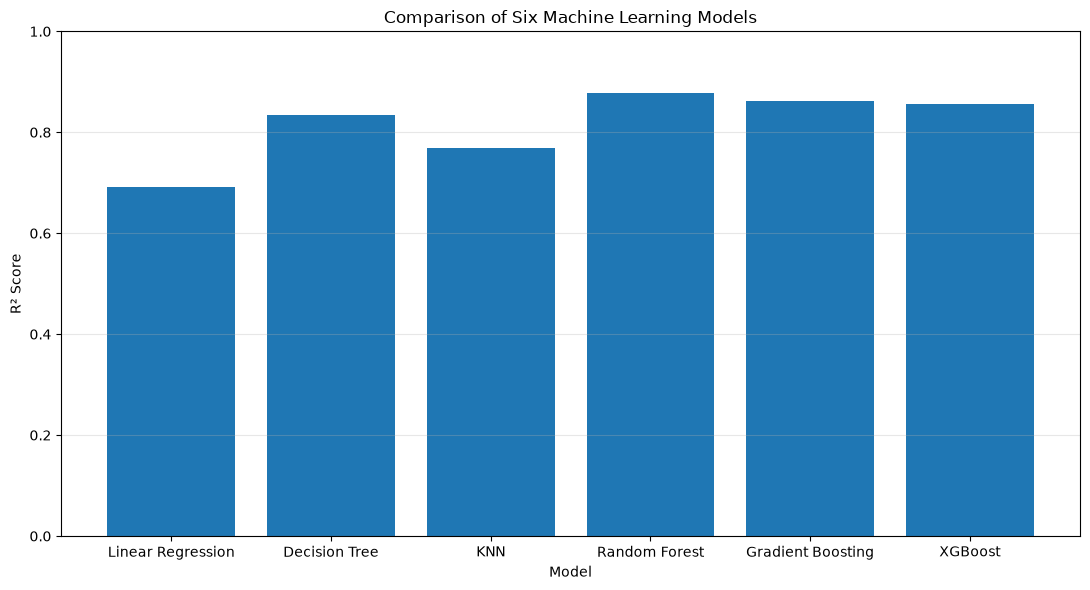

In [51]:
plt.figure(figsize=(11, 6))

plt.bar(
    model_results_6_df["Model"],
    model_results_6_df["R2"]
)

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("Comparison of Six Machine Learning Models")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

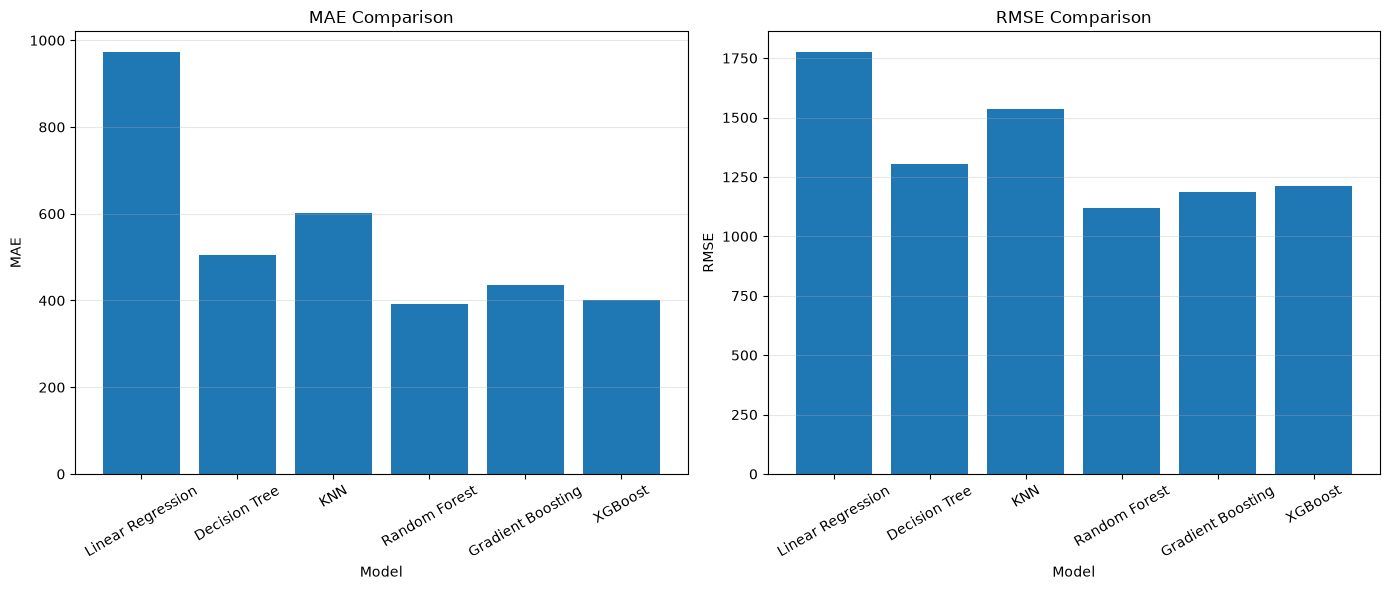

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# MAE
axes[0].bar(
    model_results_6_df["Model"],
    model_results_6_df["MAE"]
)

axes[0].set_title("MAE Comparison")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(axis="y", alpha=0.3)

# RMSE
axes[1].bar(
    model_results_6_df["Model"],
    model_results_6_df["RMSE"]
)

axes[1].set_title("RMSE Comparison")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Updated Final Results Summary

### Feature Ablation Results

The feature ablation experiment demonstrated a substantial improvement in prediction performance as richer diamond characteristics were added.

| Feature Set | MAE | RMSE | R² |
|---|---:|---:|---:|
| 4C Features | 951.62 | 2315.88 | 0.4742 |
| 4C + Dimensions | 596.25 | 1341.30 | 0.8236 |
| All 17 Features | 391.10 | 1118.07 | 0.8774 |

The R² increased from 0.4742 to 0.8774 when moving from the 4C feature set to the complete 17-feature representation.

### Six-Model Comparison

Six regression algorithms were evaluated using the same held-out test set.

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Linear Regression | 972.04 | 1774.02 | 0.6915 |
| Decision Tree | 505.49 | 1303.10 | 0.8335 |
| KNN | 602.44 | 1536.40 | 0.7686 |
| Random Forest | 391.10 | 1118.07 | 0.8774 |
| Gradient Boosting | 435.58 | 1188.66 | 0.8615 |
| XGBoost | 401.30 | 1213.81 | 0.8556 |

Random Forest obtained the highest R² and the lowest MAE and RMSE among the six evaluated models under the current experimental setup.

### Cross-Validation

Five-fold cross-validation was performed for the Random Forest model.

- Mean R²: **0.8195 ± 0.0756**
- Mean MAE: **443.40 ± 49.74**
- Mean RMSE: **1352.17 ± 249.94**

### Explainability and What-If Analysis

SHAP analysis was used to examine the contribution of processed features to individual model predictions.

Controlled What-If analysis demonstrated how changing selected diamond characteristics affected the model's estimated price. For the selected test diamond, increasing Carat Weight from 1.01 to 1.50 changed the predicted price from approximately ₹4,601 to ₹9,300, while changing Color from D to H changed the prediction to approximately ₹3,685.

These What-If results represent model sensitivity under controlled scenarios and should not be interpreted as causal effects or guaranteed market prices.

## Updated Research Findings

The experimental results provide the following findings:

1. **Feature enrichment substantially improves prediction performance.**  
   The feature ablation study shows that moving from the traditional 4C feature set to the complete 17-feature representation increased R² from 0.4742 to 0.8774.

2. **Dimensional characteristics provide substantial predictive information.**  
   Adding Length, Width, Height, Depth %, Table %, and Length/Width Ratio increased R² from 0.4742 to 0.8236.

3. **Additional physical and quality characteristics provide further improvement.**  
   Adding Shape, Polish, Symmetry, Girdle, Culet, Fluorescence, and Type increased R² from 0.8236 to 0.8774.

4. **Random Forest performed strongest in the six-model test-set comparison.**  
   Random Forest achieved an R² of 0.8774, MAE of 391.10, and RMSE of 1118.07. These were the strongest values among the six evaluated models under the current experimental setup.

5. **Different algorithms show substantially different performance.**  
   Linear Regression achieved an R² of 0.6915, while Decision Tree and KNN achieved 0.8335 and 0.7686 respectively. Gradient Boosting and XGBoost achieved 0.8615 and 0.8556 respectively.

6. **Cross-validation indicates variation across data partitions.**  
   Five-fold cross-validation of Random Forest produced a mean R² of 0.8195 ± 0.0756, showing that performance varies across different training-validation partitions.

7. **SHAP provides feature-level explanations.**  
   SHAP analysis identified Type_GIA, Carat Weight, Length, and Width among the most influential processed features in the sampled Random Forest predictions.

8. **What-If analysis demonstrates model sensitivity.**  
   Controlled changes in diamond characteristics produced noticeable changes in predicted prices, demonstrating how the model can be used for individual scenario analysis.

9. **Model-based effects should not be interpreted causally.**  
   SHAP contributions and What-If changes describe the behavior of the trained model on the available data. They do not establish causal relationships or guarantee actual market prices.

## Six-Model Experimental Comparison

To evaluate the predictive performance of different regression approaches, six machine-learning algorithms were compared using the same training and testing data and the same evaluation metrics.

The evaluated models were:

1. Linear Regression
2. Decision Tree Regressor
3. K-Nearest Neighbors (KNN) Regressor
4. Random Forest Regressor
5. Gradient Boosting Regressor
6. XGBoost Regressor

The models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R².

Among the evaluated models, Random Forest obtained an R² of 0.8774, MAE of 391.10, and RMSE of 1118.07 on the held-out test set.

These results are specific to the current dataset, preprocessing pipeline, model configurations, and train-test split.


## Updated Conclusion

This study developed an explainable and robust machine-learning framework for diamond price prediction using a richer set of diamond characteristics.

The feature ablation experiment demonstrated that expanding the feature representation beyond traditional 4C characteristics substantially improved prediction performance. The R² increased from **0.4742** using the 4C feature set to **0.8236** after adding dimensional characteristics and to **0.8774** using the complete 17-feature representation.

Six regression algorithms were evaluated using the same held-out test set: Linear Regression, Decision Tree, KNN, Random Forest, Gradient Boosting, and XGBoost. Among these models, Random Forest achieved the strongest performance under the current experimental setup, with an R² of **0.8774**, MAE of **391.10**, and RMSE of **1118.07**.

Five-fold cross-validation of Random Forest produced a mean R² of **0.8195 ± 0.0756**, providing an additional assessment of performance across different data partitions.

The framework also incorporated SHAP-based explainability and controlled What-If analysis. SHAP was used to investigate feature contributions, while What-If analysis demonstrated how controlled changes in diamond characteristics can affect model-estimated prices.

Overall, the study demonstrates that combining feature enrichment, systematic feature ablation, multi-model evaluation, cross-validation, explainability, and What-If analysis provides a more comprehensive framework for diamond price prediction than evaluating prediction accuracy alone.

The findings are specific to the available dataset, preprocessing pipeline, model configurations, and experimental setup. External validation using independent datasets would be required to assess broader generalization.

## Hyperparameter Optimization

The baseline experiments used fixed model configurations. To investigate whether the predictive performance can be further improved, hyperparameter optimization is performed for the Random Forest Regressor.

Randomized Search with five-fold cross-validation is used to evaluate different combinations of Random Forest hyperparameters.

The optimized model is then evaluated on the same held-out test set used in the baseline experiments.

In [56]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

rf_tuning = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 15, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 0.7, 1.0]
}

rf_search = RandomizedSearchCV(
    estimator=rf_tuning,
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train_processed, y_train)

print("Hyperparameter optimization completed!")
print("\nBest Parameters:")
print(rf_search.best_params_)

print("\nBest Cross-Validation R²:")
print(round(rf_search.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Hyperparameter optimization completed!

Best Parameters:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 0.7, 'max_depth': None}

Best Cross-Validation R²:
0.856


In [57]:
best_rf = rf_search.best_estimator_

tuned_predictions = best_rf.predict(X_test_processed)

tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_predictions))
tuned_r2 = r2_score(y_test, tuned_predictions)

print("Optimized Random Forest - Test Set Results")
print("-------------------------------------------")
print(f"MAE  : {tuned_mae:.4f}")
print(f"RMSE : {tuned_rmse:.4f}")
print(f"R²   : {tuned_r2:.4f}")

Optimized Random Forest - Test Set Results
-------------------------------------------
MAE  : 386.8777
RMSE : 1097.1843
R²   : 0.8820


## XGBoost Hyperparameter Optimization

To further investigate model performance, hyperparameter optimization is also performed for the XGBoost Regressor.

Randomized Search with five-fold cross-validation is used to evaluate different combinations of tree depth, learning rate, number of estimators, subsampling, and column sampling parameters.

The optimized XGBoost model is evaluated on the same held-out test set used in the baseline experiments.

In [58]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV

xgb_tuning = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma": [0, 0.1, 0.3]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_tuning,
    param_distributions=xgb_param_grid,
    n_iter=20,
    cv=5,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train_processed, y_train)

print("XGBoost hyperparameter optimization completed!")

print("\nBest Parameters:")
print(xgb_search.best_params_)

print("\nBest Cross-Validation R²:")
print(round(xgb_search.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
XGBoost hyperparameter optimization completed!

Best Parameters:
{'subsample': 0.7, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.01, 'gamma': 0.1, 'colsample_bytree': 0.7}

Best Cross-Validation R²:
0.8598


In [59]:
best_xgb = xgb_search.best_estimator_

xgb_tuned_predictions = best_xgb.predict(X_test_processed)

xgb_tuned_mae = mean_absolute_error(
    y_test,
    xgb_tuned_predictions
)

xgb_tuned_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        xgb_tuned_predictions
    )
)

xgb_tuned_r2 = r2_score(
    y_test,
    xgb_tuned_predictions
)

print("Optimized XGBoost - Test Set Results")
print("------------------------------------")
print(f"MAE  : {xgb_tuned_mae:.4f}")
print(f"RMSE : {xgb_tuned_rmse:.4f}")
print(f"R²   : {xgb_tuned_r2:.4f}")

Optimized XGBoost - Test Set Results
------------------------------------
MAE  : 426.5383
RMSE : 1124.5301
R²   : 0.8760


## Data Quality Improvement and Feature Engineering

Before final model selection, the dataset is further examined for data-quality issues and meaningful feature relationships.

The purpose of this stage is not to artificially increase model performance, but to improve the representation of diamond characteristics using valid data-cleaning and domain-relevant feature engineering techniques.

The analysis focuses on:

- Detecting inconsistent or suspicious numerical values
- Checking categorical value consistency
- Examining dimensional relationships
- Creating meaningful geometry-based features
- Checking for potential target leakage

In [60]:
numeric_columns = [
    "Carat Weight",
    "Length/Width Ratio",
    "Depth %",
    "Table %",
    "Length",
    "Width",
    "Height",
    "Price"
]

print("Numerical Data Quality Check")
print("=" * 40)

for column in numeric_columns:
    print(f"\n{column}")
    print("Minimum:", df[column].min())
    print("Maximum:", df[column].max())
    print("Missing:", df[column].isna().sum())

Numerical Data Quality Check

Carat Weight
Minimum: 1.0
Maximum: 9.38
Missing: 5

Length/Width Ratio
Minimum: 1.0
Maximum: 2.58
Missing: 5

Depth %
Minimum: 46.1
Maximum: 77.0
Missing: 7

Table %
Minimum: 51.0
Maximum: 78.0
Missing: 17

Length
Minimum: 5.18
Maximum: 15.21
Missing: 20

Width
Minimum: 4.42
Maximum: 14.88
Missing: 20

Height
Minimum: 2.67
Maximum: 8.17
Missing: 20

Price
Minimum: 1010
Maximum: 39460
Missing: 0


In [61]:
print("Dimensional Consistency Check")
print("=" * 40)

# Calculated Length/Width ratio
calculated_ratio = df["Length"] / df["Width"]

ratio_difference = (
    calculated_ratio - df["Length/Width Ratio"]
).abs()

print(
    "Large Length/Width Ratio differences (> 0.05):",
    (ratio_difference > 0.05).sum()
)

# Check physical dimension relationships
print(
    "Length <= Width:",
    (df["Length"] <= df["Width"]).sum()
)

print(
    "Height >= Length:",
    (df["Height"] >= df["Length"]).sum()
)

print(
    "Height >= Width:",
    (df["Height"] >= df["Width"]).sum()
)

# Show suspicious rows
suspicious_dimensions = df[
    (ratio_difference > 0.05) |
    (df["Length"] <= df["Width"]) |
    (df["Height"] >= df["Length"]) |
    (df["Height"] >= df["Width"])
]

print("\nSuspicious dimensional records:", len(suspicious_dimensions))

display(
    suspicious_dimensions[
        [
            "Length",
            "Width",
            "Height",
            "Length/Width Ratio",
            "Depth %",
            "Table %",
            "Carat Weight",
            "Price"
        ]
    ].head(20)
)

Dimensional Consistency Check
Large Length/Width Ratio differences (> 0.05): 821
Length <= Width: 1765
Height >= Length: 0
Height >= Width: 0

Suspicious dimensional records: 1765


,Length,Width,Height,Length/Width Ratio,Depth %,Table %,Carat Weight,Price
3,5.85,6.89,4.25,1.18,61.7,58.0,1.00,7110
7,12.32,13.83,7.69,1.12,55.6,58.0,7.54,16910
9,7.30,8.40,4.93,1.15,58.7,57.0,1.75,3540
15,7.52,7.55,4.59,1.00,60.9,59.0,1.59,1850
28,6.44,6.46,3.89,1.00,60.3,62.0,1.00,4020
32,7.48,7.49,4.64,1.00,62.0,57.0,1.60,1800
37,7.43,7.46,4.49,1.00,60.3,58.0,1.51,1770
46,6.00,6.78,4.29,1.13,63.2,61.0,1.01,7360
49,6.20,6.27,4.01,1.01,64.4,57.0,1.01,4100
53,5.18,5.18,3.97,1.00,76.6,71.0,1.01,2530


In [62]:
# Create a copy so the original cleaned dataset remains unchanged
df_engineered = df.copy()

# Geometric volume approximation
df_engineered["Volume"] = (
    df_engineered["Length"]
    * df_engineered["Width"]
    * df_engineered["Height"]
)

# Footprint area
df_engineered["Length_Width_Area"] = (
    df_engineered["Length"]
    * df_engineered["Width"]
)

# Length-to-height ratio
df_engineered["Length_Height_Ratio"] = (
    df_engineered["Length"]
    / df_engineered["Height"]
)

# Width-to-height ratio
df_engineered["Width_Height_Ratio"] = (
    df_engineered["Width"]
    / df_engineered["Height"]
)

# Carat relative to estimated volume
df_engineered["Carat_Volume_Ratio"] = (
    df_engineered["Carat Weight"]
    / df_engineered["Volume"]
)

print("Feature engineering completed!")
print("New shape:", df_engineered.shape)

display(
    df_engineered[
        [
            "Length",
            "Width",
            "Height",
            "Carat Weight",
            "Volume",
            "Length_Width_Area",
            "Length_Height_Ratio",
            "Width_Height_Ratio",
            "Carat_Volume_Ratio"
        ]
    ].head()
)

Feature engineering completed!
New shape: (6482, 23)


,Length,Width,Height,Carat Weight,Volume,Length_Width_Area,Length_Height_Ratio,Width_Height_Ratio,Carat_Volume_Ratio
0,7.09,6.95,4.57,1.84,225.189035,49.2755,1.551422,1.520788,0.008171
1,9.64,5.86,3.66,1.20,206.754864,56.4904,2.633880,1.601093,0.005804
2,8.44,6.00,3.79,1.19,191.925600,50.6400,2.226913,1.583113,0.006200
3,5.85,6.89,4.25,1.00,171.302625,40.3065,1.376471,1.621176,0.005838
4,6.80,5.05,3.50,1.01,120.190000,34.3400,1.942857,1.442857,0.008403


In [68]:
engineered_features = [
    "Volume",
    "Length_Width_Area",
    "Length_Height_Ratio",
    "Width_Height_Ratio",
    "Carat_Volume_Ratio"
]

correlation_check = (
    df_engineered[engineered_features + ["Price"]]
    .corr()["Price"]
    .sort_values(ascending=False)
)

print("Engineered Feature Correlation with Price")
print("=" * 45)

display(correlation_check)

Engineered Feature Correlation with Price


Price                  1.000000
Length_Width_Area      0.431627
Volume                 0.397167
Width_Height_Ratio     0.189078
Length_Height_Ratio    0.126831
Carat_Volume_Ratio    -0.165425
Name: Price, dtype: float64

In [66]:
# Create the 19-feature dataset
df_model = df_engineered.copy()

geometry_features = [
    "Length_Width_Area",
    "Volume"
]

base_features = [
    "Shape",
    "Cut",
    "Color",
    "Clarity",
    "Carat Weight",
    "Length/Width Ratio",
    "Depth %",
    "Table %",
    "Polish",
    "Symmetry",
    "Girdle",
    "Culet",
    "Length",
    "Width",
    "Height",
    "Type",
    "Fluorescence"
]

final_features_19 = base_features + geometry_features

print("Number of features:", len(final_features_19))
print("\nFeatures:")
for feature in final_features_19:
    print("-", feature)

Number of features: 19

Features:
- Shape
- Cut
- Color
- Clarity
- Carat Weight
- Length/Width Ratio
- Depth %
- Table %
- Polish
- Symmetry
- Girdle
- Culet
- Length
- Width
- Height
- Type
- Fluorescence
- Length_Width_Area
- Volume


In [69]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# ==========================================
# 1. Prepare 19-feature dataset
# ==========================================

X_19 = df_engineered[final_features_19]
y_19 = df_engineered["Price"]

X_train_19, X_test_19, y_train_19, y_test_19 = train_test_split(
    X_19,
    y_19,
    test_size=0.20,
    random_state=42
)

# ==========================================
# 2. Define feature groups
# ==========================================

categorical_19 = [
    feature
    for feature in categorical_features
    if feature in final_features_19
]

numerical_19 = [
    feature
    for feature in numerical_features
    if feature in final_features_19
]

# Add engineered numerical features
numerical_19 += geometry_features

# ==========================================
# 3. Preprocessing
# ==========================================

preprocessor_19 = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        numerical_19
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(
                strategy="constant",
                fill_value="Unknown"
            )),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore"
            ))
        ]),
        categorical_19
    )
])

# ==========================================
# 4. Transform data
# ==========================================

X_train_19_processed = preprocessor_19.fit_transform(
    X_train_19
)

X_test_19_processed = preprocessor_19.transform(
    X_test_19
)

print("19-feature preprocessing completed!")
print("Training shape:", X_train_19_processed.shape)
print("Testing shape:", X_test_19_processed.shape)

# ==========================================
# 5. Tuned Random Forest
# ==========================================

best_rf_19 = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=4,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

best_rf_19.fit(
    X_train_19_processed,
    y_train_19
)

# ==========================================
# 6. Prediction
# ==========================================

predictions_19 = best_rf_19.predict(
    X_test_19_processed
)

# ==========================================
# 7. Evaluation
# ==========================================

mae_19 = mean_absolute_error(
    y_test_19,
    predictions_19
)

rmse_19 = np.sqrt(
    mean_squared_error(
        y_test_19,
        predictions_19
    )
)

r2_19 = r2_score(
    y_test_19,
    predictions_19
)

print("\n19-Feature Tuned Random Forest")
print("--------------------------------")
print(f"MAE  : {mae_19:.4f}")
print(f"RMSE : {rmse_19:.4f}")
print(f"R²   : {r2_19:.4f}")

19-feature preprocessing completed!
Training shape: (5185, 90)
Testing shape: (1297, 90)

19-Feature Tuned Random Forest
--------------------------------
MAE  : 394.4235
RMSE : 1116.7079
R²   : 0.8777


## Error Analysis

Error analysis is performed to understand where the final Random Forest model makes larger prediction errors.

The analysis examines:

- Absolute prediction error
- Error distribution
- Relationship between error and actual diamond price
- Diamonds with the largest prediction errors

This analysis helps identify patterns in model performance that may not be visible from overall MAE, RMSE, and R² metrics alone.

In [70]:
# Use the optimized 17-feature Random Forest
final_predictions = best_rf.predict(X_test_processed)

error_analysis = X_test.copy()

error_analysis["Actual Price"] = y_test.values
error_analysis["Predicted Price"] = final_predictions

error_analysis["Absolute Error"] = (
    error_analysis["Actual Price"]
    - error_analysis["Predicted Price"]
).abs()

error_analysis["Percentage Error"] = (
    error_analysis["Absolute Error"]
    / error_analysis["Actual Price"]
) * 100

print("Error analysis dataset created!")
print("Number of test records:", len(error_analysis))

display(error_analysis.head())

Error analysis dataset created!
Number of test records: 1297


,Shape,Cut,Color,Clarity,Carat Weight,Length/Width Ratio,Depth %,Table %,Polish,Symmetry,...,Culet,Length,Width,Height,Type,Fluorescence,Actual Price,Predicted Price,Absolute Error,Percentage Error
3558,Pear,NaN,D,VS2,1.01,1.53,64.2,56.0,Excellent,Excellent,...,NaN,8.36,5.48,3.52,GIA,NaN,4390,4671.747865,281.747865,6.417947
3903,Princess,Ideal,H,VS1,1.06,1.00,74.9,67.0,Excellent,Excellent,...,NaN,5.50,5.50,4.12,GIA,NaN,3600,3340.443252,259.556748,7.209910
2131,Round,Excellent,H,VS1,1.00,1.01,58.9,62.0,Excellent,Excellent,...,NaN,6.49,6.54,3.84,GIA,NaN,4040,4161.740427,121.740427,3.013377
351,Oval,NaN,D,VS1,1.01,1.42,60.1,60.0,Excellent,Excellent,...,Pointed,8.20,5.76,3.46,IGI Lab-Grown,NaN,1070,1066.741822,3.258178,0.304503
3422,Oval,NaN,H,VS2,1.20,1.36,63.8,57.0,Excellent,Excellent,...,NaN,8.12,5.96,3.80,GIA,Strong,5220,4588.074583,631.925417,12.105851


In [71]:
print("Error Analysis Summary")
print("=" * 40)

print(
    f"Mean Absolute Error: "
    f"₹{error_analysis['Absolute Error'].mean():,.2f}"
)

print(
    f"Median Absolute Error: "
    f"₹{error_analysis['Absolute Error'].median():,.2f}"
)

print(
    f"Maximum Absolute Error: "
    f"₹{error_analysis['Absolute Error'].max():,.2f}"
)

print(
    f"Mean Percentage Error: "
    f"{error_analysis['Percentage Error'].mean():.2f}%"
)

Error Analysis Summary
Mean Absolute Error: ₹386.88
Median Absolute Error: ₹115.01
Maximum Absolute Error: ₹17,670.03
Mean Percentage Error: 10.44%


In [72]:
largest_errors = (
    error_analysis
    .sort_values("Absolute Error", ascending=False)
    .head(15)
)

print("Top 15 Largest Prediction Errors")
print("=" * 50)

display(
    largest_errors[
        [
            "Actual Price",
            "Predicted Price",
            "Absolute Error",
            "Percentage Error",
            "Shape",
            "Cut",
            "Color",
            "Clarity",
            "Carat Weight",
            "Type"
        ]
    ]
)


Top 15 Largest Prediction Errors


,Actual Price,Predicted Price,Absolute Error,Percentage Error,Shape,Cut,Color,Clarity,Carat Weight,Type
349,27040,9369.972394,17670.027606,65.347735,Heart,NaN,F,VS1,4.07,GIA Lab-Grown
3662,4090,18753.785383,14663.785383,358.527760,Marquise,NaN,D,VS2,1.71,GIA
3070,13720,1845.252908,11874.747092,86.550635,Round,Ideal,D,VS1,1.55,IGI Lab-Grown
101,36510,24827.470605,11682.529395,31.998163,Marquise,NaN,E,VVS2,2.08,GIA
947,1390,9241.602153,7851.602153,564.863464,Heart,NaN,H,VS2,1.70,GIA
2776,1030,8677.412814,7647.412814,742.467263,Heart,NaN,E,VS1,3.73,GIA Lab-Grown
3265,38710,31890.982358,6819.017642,17.615649,Marquise,NaN,H,VS1,3.17,GIA
6241,18480,25054.058292,6574.058292,35.573909,Marquise,NaN,G,VS2,1.97,GIA
3285,1840,8189.944261,6349.944261,345.105666,Marquise,NaN,F,IF,1.30,GIA
1074,2790,8315.048374,5525.048374,198.030408,Heart,NaN,F,VS1,1.50,GIA


In [73]:
# Error analysis by Shape and Type

shape_error = (
    error_analysis
    .groupby("Shape")
    .agg(
        Count=("Absolute Error", "size"),
        Mean_MAE=("Absolute Error", "mean"),
        Median_Error=("Absolute Error", "median"),
        Mean_Percentage_Error=("Percentage Error", "mean")
    )
    .sort_values("Mean_MAE", ascending=False)
)

type_error = (
    error_analysis
    .groupby("Type")
    .agg(
        Count=("Absolute Error", "size"),
        Mean_MAE=("Absolute Error", "mean"),
        Median_Error=("Absolute Error", "median"),
        Mean_Percentage_Error=("Percentage Error", "mean")
    )
    .sort_values("Mean_MAE", ascending=False)
)

print("Error Analysis by Shape")
print("=" * 50)
display(shape_error.round(2))

print("\nError Analysis by Diamond Type")
print("=" * 50)
display(type_error.round(2))

Error Analysis by Shape


,Count,Mean_MAE,Median_Error,Mean_Percentage_Error
Shape,,,,
Heart,172,849.07,445.15,24.32
Marquise,151,743.68,81.24,11.58
Cushion Modified,64,504.57,367.76,13.28
Cushion,17,478.53,410.51,16.28
Radiant,166,251.85,51.59,7.44
Oval,167,249.85,19.71,8.96
Round,169,235.05,79.74,7.69
Emerald,32,228.24,141.60,8.71
Princess,173,217.20,54.18,6.64



Error Analysis by Diamond Type


,Count,Mean_MAE,Median_Error,Mean_Percentage_Error
Type,,,,
GIA,654,582.45,328.94,14.63
GIA Lab-Grown,236,356.22,51.55,10.72
IGI Lab-Grown,407,90.39,12.41,3.52


## Error Analysis Findings

The error analysis provides additional insight into the behavior of the optimized Random Forest model.

The model achieved a Mean Absolute Error (MAE) of **₹386.88**, while the median absolute error was **₹115.01**. The difference between the mean and median error indicates that most predictions have relatively smaller errors, while a smaller number of observations produce substantially larger errors.

The maximum observed absolute error was **₹17,670.03**. Examination of the largest-error predictions showed that some difficult cases occur among Heart and Marquise shaped diamonds and across different diamond certification/types.

### Error Variation by Diamond Type

The error analysis also revealed substantial variation across diamond types:

| Diamond Type | Count | Mean MAE | Median Error | Mean Percentage Error |
|---|---:|---:|---:|---:|
| GIA | 654 | ₹582.45 | ₹328.94 | 14.63% |
| GIA Lab-Grown | 236 | ₹356.22 | ₹51.55 | 10.72% |
| IGI Lab-Grown | 407 | ₹90.39 | ₹12.41 | 3.52% |

The GIA group showed the largest mean absolute error among the three groups, while IGI Lab-Grown diamonds showed substantially lower prediction errors.

These differences indicate that the model does not perform uniformly across all diamond types. Differences in the observed pricing patterns, feature distributions, and sample characteristics between groups may contribute to this variation.

The large individual errors should not automatically be treated as incorrect or invalid records. They represent observations for which the trained model has difficulty reproducing the observed price.

Therefore, the error analysis supports the need for group-wise evaluation and external validation when assessing the generalization of diamond price prediction models.

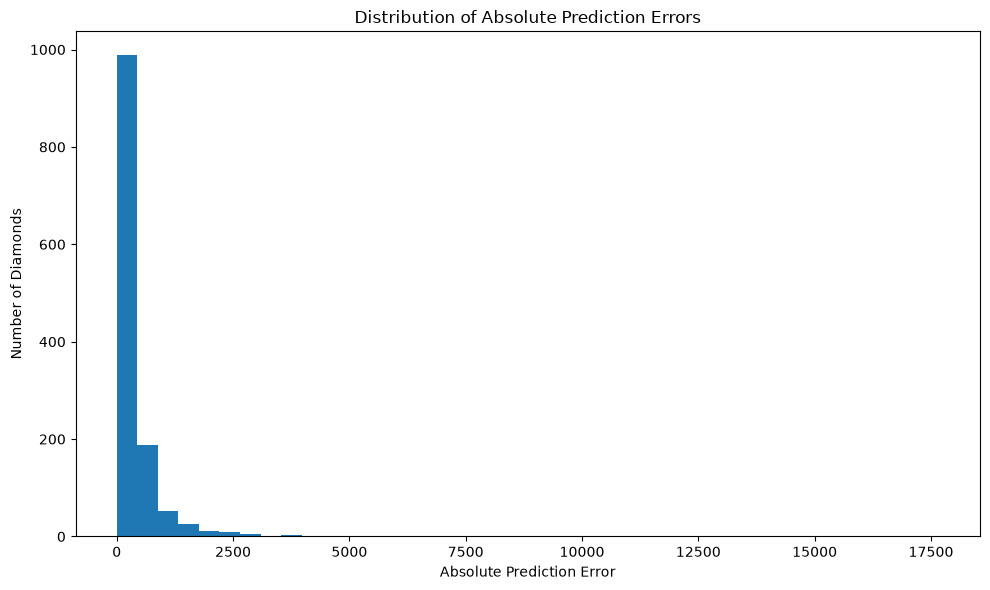

In [75]:
plt.figure(figsize=(10, 6))

plt.hist(
    error_analysis["Absolute Error"],
    bins=40
)

plt.xlabel("Absolute Prediction Error")
plt.ylabel("Number of Diamonds")
plt.title("Distribution of Absolute Prediction Errors")

plt.tight_layout()
plt.show()

## Ensemble Model Optimization

The individual Random Forest and XGBoost models capture different patterns in the diamond pricing data. To investigate whether their complementary predictions can improve generalization, an ensemble model is constructed.

The ensemble weight is selected using five-fold out-of-fold predictions on the training data. The held-out test set is used only for the final evaluation.

This prevents the test set from influencing ensemble weight selection.

In [77]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.base import clone

# --------------------------------------------------
# 1. Create fresh copies of the tuned models
# --------------------------------------------------

rf_ensemble = clone(best_rf)

xgb_ensemble = clone(best_xgb)

# --------------------------------------------------
# 2. Five-fold cross-validation
# --------------------------------------------------

ensemble_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Generating out-of-fold predictions...")
print("This may take some time...")

rf_oof = cross_val_predict(
    rf_ensemble,
    X_train_processed,
    y_train,
    cv=ensemble_cv,
    n_jobs=-1
)

xgb_oof = cross_val_predict(
    xgb_ensemble,
    X_train_processed,
    y_train,
    cv=ensemble_cv,
    n_jobs=-1
)

print("Out-of-fold predictions generated successfully!")

# --------------------------------------------------
# 3. Find the best ensemble weight
# --------------------------------------------------

weights = np.arange(0.0, 1.01, 0.05)

ensemble_cv_results = []

for rf_weight in weights:

    xgb_weight = 1 - rf_weight

    blended_prediction = (
        rf_weight * rf_oof
        + xgb_weight * xgb_oof
    )

    mae = mean_absolute_error(
        y_train,
        blended_prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_train,
            blended_prediction
        )
    )

    r2 = r2_score(
        y_train,
        blended_prediction
    )

    ensemble_cv_results.append({
        "RF Weight": rf_weight,
        "XGBoost Weight": xgb_weight,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

ensemble_cv_df = pd.DataFrame(
    ensemble_cv_results
)

best_weight_row = ensemble_cv_df.loc[
    ensemble_cv_df["R2"].idxmax()
]

print("\nBest Ensemble Weights")
print("----------------------")
print(
    f"Random Forest Weight: "
    f"{best_weight_row['RF Weight']:.2f}"
)

print(
    f"XGBoost Weight: "
    f"{best_weight_row['XGBoost Weight']:.2f}"
)

print(
    f"OOF R²: "
    f"{best_weight_row['R2']:.4f}"
)

display(
    ensemble_cv_df.round(4)
)

Generating out-of-fold predictions...
This may take some time...
Out-of-fold predictions generated successfully!

Best Ensemble Weights
----------------------
Random Forest Weight: 0.50
XGBoost Weight: 0.50
OOF R²: 0.8467


,RF Weight,XGBoost Weight,MAE,RMSE,R2
0,0.00,1.00,449.7401,1302.6769,0.8443
1,0.05,0.95,447.1708,1300.6710,0.8448
2,0.10,0.90,444.7870,1298.8830,0.8452
3,0.15,0.85,442.5130,1297.3137,0.8456
4,0.20,0.80,440.5053,1295.9639,0.8459
5,0.25,0.75,438.6853,1294.8344,0.8462
6,0.30,0.70,437.0851,1293.9257,0.8464
7,0.35,0.65,435.6493,1293.2383,0.8465
8,0.40,0.60,434.3704,1292.7724,0.8466
9,0.45,0.55,433.2958,1292.5285,0.8467


In [78]:
# --------------------------------------------------
# 4. Train both tuned models on full training data
# --------------------------------------------------

rf_final_ensemble = clone(best_rf)
xgb_final_ensemble = clone(best_xgb)

rf_final_ensemble.fit(
    X_train_processed,
    y_train
)

xgb_final_ensemble.fit(
    X_train_processed,
    y_train
)

# --------------------------------------------------
# 5. Test-set predictions
# --------------------------------------------------

rf_test_pred = rf_final_ensemble.predict(
    X_test_processed
)

xgb_test_pred = xgb_final_ensemble.predict(
    X_test_processed
)

# Best weight selected ONLY from training OOF predictions
rf_weight = best_weight_row["RF Weight"]
xgb_weight = best_weight_row["XGBoost Weight"]

ensemble_test_pred = (
    rf_weight * rf_test_pred
    + xgb_weight * xgb_test_pred
)

# --------------------------------------------------
# 6. Final evaluation
# --------------------------------------------------

ensemble_mae = mean_absolute_error(
    y_test,
    ensemble_test_pred
)

ensemble_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        ensemble_test_pred
    )
)

ensemble_r2 = r2_score(
    y_test,
    ensemble_test_pred
)

print("\nFinal Ensemble Test Results")
print("============================")
print(f"MAE  : {ensemble_mae:.4f}")
print(f"RMSE : {ensemble_rmse:.4f}")
print(f"R²   : {ensemble_r2:.4f}")


Final Ensemble Test Results
MAE  : 398.3414
RMSE : 1097.0541
R²   : 0.8820


In [79]:
# ==========================================
# DATA QUALITY AUDIT
# ==========================================

import pandas as pd
import numpy as np

audit_df = df.copy()

# 1. Check impossible / suspicious numeric values
print("===== NUMERIC RANGE CHECK =====")

numeric_cols = [
    "Carat Weight", "Length/Width Ratio",
    "Depth %", "Table %",
    "Length", "Width", "Height", "Price"
]

for col in numeric_cols:
    print(
        f"{col:25s} | "
        f"Min = {audit_df[col].min()} | "
        f"Max = {audit_df[col].max()} | "
        f"Missing = {audit_df[col].isna().sum()}"
    )


# 2. Check whether L/W Ratio matches Length / Width
audit_df["Calculated_LW_Ratio"] = (
    audit_df["Length"] / audit_df["Width"]
)

audit_df["LW_Ratio_Error"] = abs(
    audit_df["Calculated_LW_Ratio"] -
    audit_df["Length/Width Ratio"]
)

ratio_issues = audit_df[
    audit_df["LW_Ratio_Error"] > 0.03
]

print("\n===== LENGTH/WIDTH RATIO INCONSISTENCIES =====")
print("Rows with ratio difference > 0.03:", len(ratio_issues))

display(
    ratio_issues[
        [
            "Shape",
            "Carat Weight",
            "Length",
            "Width",
            "Length/Width Ratio",
            "Calculated_LW_Ratio",
            "LW_Ratio_Error",
            "Price",
            "Type"
        ]
    ].head(20)
)


# 3. Check physically suspicious dimensions
dimension_issues = audit_df[
    (audit_df["Length"] <= 0) |
    (audit_df["Width"] <= 0) |
    (audit_df["Height"] <= 0) |
    (audit_df["Depth %"] <= 0) |
    (audit_df["Table %"] <= 0) |
    (audit_df["Price"] <= 0)
]

print("\n===== INVALID NUMERIC VALUES =====")
print("Suspicious rows:", len(dimension_issues))

display(
    dimension_issues[
        [
            "Shape", "Carat Weight",
            "Length", "Width", "Height",
            "Depth %", "Table %",
            "Price", "Type"
        ]
    ].head(20)
)


# 4. Check duplicate feature combinations
feature_cols = [
    "Shape", "Cut", "Color", "Clarity",
    "Carat Weight", "Length/Width Ratio",
    "Depth %", "Table %",
    "Polish", "Symmetry", "Girdle",
    "Culet", "Length", "Width", "Height",
    "Type", "Fluorescence"
]

feature_duplicates = audit_df[
    audit_df.duplicated(
        subset=feature_cols,
        keep=False
    )
].sort_values(feature_cols)

print("\n===== SAME FEATURES, POSSIBLY DIFFERENT PRICE =====")
print("Rows involved:", len(feature_duplicates))

display(
    feature_duplicates[
        feature_cols + ["Price"]
    ].head(30)
)


# 5. Price variation among identical feature combinations
price_variation = (
    audit_df
    .groupby(feature_cols, dropna=False)["Price"]
    .agg(["count", "min", "max", "std"])
    .reset_index()
)

price_variation = price_variation[
    (price_variation["count"] > 1) &
    (price_variation["max"] != price_variation["min"])
]

print("\n===== IDENTICAL FEATURES BUT DIFFERENT PRICES =====")
print("Groups:", len(price_variation))

display(
    price_variation
    .sort_values("std", ascending=False)
    .head(20)
)

===== NUMERIC RANGE CHECK =====
Carat Weight              | Min = 1.0 | Max = 9.38 | Missing = 5
Length/Width Ratio        | Min = 1.0 | Max = 2.58 | Missing = 5
Depth %                   | Min = 46.1 | Max = 77.0 | Missing = 7
Table %                   | Min = 51.0 | Max = 78.0 | Missing = 17
Length                    | Min = 5.18 | Max = 15.21 | Missing = 20
Width                     | Min = 4.42 | Max = 14.88 | Missing = 20
Height                    | Min = 2.67 | Max = 8.17 | Missing = 20
Price                     | Min = 1010 | Max = 39460 | Missing = 0

===== LENGTH/WIDTH RATIO INCONSISTENCIES =====
Rows with ratio difference > 0.03: 827


,Shape,Carat Weight,Length,Width,Length/Width Ratio,Calculated_LW_Ratio,LW_Ratio_Error,Price,Type
3,Heart,1.00,5.85,6.89,1.18,0.849057,0.330943,7110,GIA
7,Heart,7.54,12.32,13.83,1.12,0.890817,0.229183,16910,GIA Lab-Grown
9,Heart,1.75,7.30,8.40,1.15,0.869048,0.280952,3540,GIA Lab-Grown
46,Heart,1.01,6.00,6.78,1.13,0.884956,0.245044,7360,GIA
54,Heart,1.06,6.21,7.30,1.18,0.850685,0.329315,3860,GIA
62,Heart,4.47,10.01,11.54,1.15,0.867418,0.282582,11090,GIA Lab-Grown
66,Heart,1.02,5.92,7.04,1.19,0.840909,0.349091,9530,GIA
67,Heart,1.52,6.95,8.16,1.17,0.851716,0.318284,9730,GIA
97,Heart,2.09,7.90,9.06,1.15,0.871965,0.278035,5090,IGI Lab-Grown
107,Heart,1.73,7.31,8.56,1.17,0.853972,0.316028,2480,GIA Lab-Grown



===== INVALID NUMERIC VALUES =====
Suspicious rows: 0


,Shape,Carat Weight,Length,Width,Height,Depth %,Table %,Price,Type



===== SAME FEATURES, POSSIBLY DIFFERENT PRICE =====
Rows involved: 7


,Shape,Cut,Color,Clarity,Carat Weight,Length/Width Ratio,Depth %,Table %,Polish,Symmetry,Girdle,Culet,Length,Width,Height,Type,Fluorescence,Price
4389,Round,Excellent,H,VS1,1.01,1.01,62.5,58.0,Excellent,Excellent,Medium to Slightly Thick,NaN,6.37,6.41,3.99,GIA,Faint,4120
5378,Round,Excellent,H,VS1,1.01,1.01,62.5,58.0,Excellent,Excellent,Medium to Slightly Thick,NaN,6.37,6.41,3.99,GIA,Faint,3880
1948,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GIA,NaN,3350
4110,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GIA,NaN,3380
6060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GIA,NaN,4380
250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,IGI Lab-Grown,NaN,1210
5913,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,IGI Lab-Grown,NaN,2170



===== IDENTICAL FEATURES BUT DIFFERENT PRICES =====
Groups: 3


,Shape,Cut,Color,Clarity,Carat Weight,Length/Width Ratio,Depth %,Table %,Polish,Symmetry,...,Culet,Length,Width,Height,Type,Fluorescence,count,min,max,std
6477,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,IGI Lab-Grown,NaN,2,1210,2170,678.822510
6476,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,GIA,NaN,3,3350,4380,586.202468
5940,Round,Excellent,H,VS1,1.01,1.01,62.5,58.0,Excellent,Excellent,...,NaN,6.37,6.41,3.99,GIA,Faint,2,3880,4120,169.705627


In [80]:
# ==========================================
# CORRECT LENGTH/WIDTH RATIO AUDIT
# ==========================================

audit_df = df.copy()

# Check BOTH possible interpretations
audit_df["Ratio_L_div_W"] = audit_df["Length"] / audit_df["Width"]
audit_df["Ratio_W_div_L"] = audit_df["Width"] / audit_df["Length"]

# Find which interpretation is closer to the stored ratio
audit_df["Error_L_div_W"] = abs(
    audit_df["Length/Width Ratio"] - audit_df["Ratio_L_div_W"]
)

audit_df["Error_W_div_L"] = abs(
    audit_df["Length/Width Ratio"] - audit_df["Ratio_W_div_L"]
)

audit_df["Best_Ratio_Error"] = audit_df[
    ["Error_L_div_W", "Error_W_div_L"]
].min(axis=1)

# Rows where neither interpretation matches reasonably
ratio_issues = audit_df[
    audit_df["Best_Ratio_Error"] > 0.03
]

print("Total rows:", len(audit_df))
print("Rows with potentially inconsistent ratio:", len(ratio_issues))

display(
    ratio_issues[
        [
            "Shape",
            "Length",
            "Width",
            "Length/Width Ratio",
            "Ratio_L_div_W",
            "Ratio_W_div_L",
            "Error_L_div_W",
            "Error_W_div_L",
            "Price",
            "Type"
        ]
    ].head(30)
)

# Compare by shape
print("\n===== RATIO CONVENTION BY SHAPE =====")

for shape, group in audit_df.groupby("Shape", dropna=False):

    error_l = group["Error_L_div_W"].median()
    error_w = group["Error_W_div_L"].median()

    if error_l < error_w:
        convention = "Length / Width"
    else:
        convention = "Width / Length"

    print(
        f"{str(shape):20s} -> {convention:18s} | "
        f"L/W error = {error_l:.4f} | "
        f"W/L error = {error_w:.4f}"
    )

Total rows: 6482
Rows with potentially inconsistent ratio: 0


,Shape,Length,Width,Length/Width Ratio,Ratio_L_div_W,Ratio_W_div_L,Error_L_div_W,Error_W_div_L,Price,Type



===== RATIO CONVENTION BY SHAPE =====
Cushion              -> Length / Width     | L/W error = 0.0023 | W/L error = 0.0237
Cushion Modified     -> Length / Width     | L/W error = 0.0023 | W/L error = 0.0406
Emerald              -> Length / Width     | L/W error = 0.0021 | W/L error = 0.6228
Heart                -> Width / Length     | L/W error = 0.2639 | W/L error = 0.0026
Marquise             -> Length / Width     | L/W error = 0.0025 | W/L error = 1.4510
Oval                 -> Length / Width     | L/W error = 0.0025 | W/L error = 0.7167
Pear                 -> Length / Width     | L/W error = 0.0025 | W/L error = 0.9490
Princess             -> Length / Width     | L/W error = 0.0026 | W/L error = 0.0208
Radiant              -> Length / Width     | L/W error = 0.0023 | W/L error = 0.6095
Round                -> Width / Length     | L/W error = 0.0154 | W/L error = 0.0033
Square Radiant       -> Length / Width     | L/W error = 0.0018 | W/L error = 0.0034
nan                  -> Wi

In [81]:
# ==========================================
# CORRECT LENGTH/WIDTH RATIO AUDIT
# ==========================================

audit_df = df.copy()

# Check BOTH possible interpretations
audit_df["Ratio_L_div_W"] = audit_df["Length"] / audit_df["Width"]
audit_df["Ratio_W_div_L"] = audit_df["Width"] / audit_df["Length"]

# Find which interpretation is closer to the stored ratio
audit_df["Error_L_div_W"] = abs(
    audit_df["Length/Width Ratio"] - audit_df["Ratio_L_div_W"]
)

audit_df["Error_W_div_L"] = abs(
    audit_df["Length/Width Ratio"] - audit_df["Ratio_W_div_L"]
)

audit_df["Best_Ratio_Error"] = audit_df[
    ["Error_L_div_W", "Error_W_div_L"]
].min(axis=1)

# Rows where neither interpretation matches reasonably
ratio_issues = audit_df[
    audit_df["Best_Ratio_Error"] > 0.03
]

print("Total rows:", len(audit_df))
print("Rows with potentially inconsistent ratio:", len(ratio_issues))

display(
    ratio_issues[
        [
            "Shape",
            "Length",
            "Width",
            "Length/Width Ratio",
            "Ratio_L_div_W",
            "Ratio_W_div_L",
            "Error_L_div_W",
            "Error_W_div_L",
            "Price",
            "Type"
        ]
    ].head(30)
)

# Compare by shape
print("\n===== RATIO CONVENTION BY SHAPE =====")

for shape, group in audit_df.groupby("Shape", dropna=False):

    error_l = group["Error_L_div_W"].median()
    error_w = group["Error_W_div_L"].median()

    if error_l < error_w:
        convention = "Length / Width"
    else:
        convention = "Width / Length"

    print(
        f"{str(shape):20s} -> {convention:18s} | "
        f"L/W error = {error_l:.4f} | "
        f"W/L error = {error_w:.4f}"
    )

Total rows: 6482
Rows with potentially inconsistent ratio: 0


,Shape,Length,Width,Length/Width Ratio,Ratio_L_div_W,Ratio_W_div_L,Error_L_div_W,Error_W_div_L,Price,Type



===== RATIO CONVENTION BY SHAPE =====
Cushion              -> Length / Width     | L/W error = 0.0023 | W/L error = 0.0237
Cushion Modified     -> Length / Width     | L/W error = 0.0023 | W/L error = 0.0406
Emerald              -> Length / Width     | L/W error = 0.0021 | W/L error = 0.6228
Heart                -> Width / Length     | L/W error = 0.2639 | W/L error = 0.0026
Marquise             -> Length / Width     | L/W error = 0.0025 | W/L error = 1.4510
Oval                 -> Length / Width     | L/W error = 0.0025 | W/L error = 0.7167
Pear                 -> Length / Width     | L/W error = 0.0025 | W/L error = 0.9490
Princess             -> Length / Width     | L/W error = 0.0026 | W/L error = 0.0208
Radiant              -> Length / Width     | L/W error = 0.0023 | W/L error = 0.6095
Round                -> Width / Length     | L/W error = 0.0154 | W/L error = 0.0033
Square Radiant       -> Length / Width     | L/W error = 0.0018 | W/L error = 0.0034
nan                  -> Wi

In [82]:
# ==========================================
# PRICE CONSISTENCY AUDIT
# ==========================================

price_audit = df.copy()

# Create carat bins so we compare diamonds of similar weight
price_audit["Carat_Bin"] = (
    price_audit["Carat Weight"]
    .round(1)
)

# Group diamonds using major pricing characteristics
group_cols = [
    "Type",
    "Shape",
    "Color",
    "Clarity",
    "Carat_Bin"
]

group_stats = (
    price_audit
    .groupby(group_cols, dropna=False)["Price"]
    .agg(
        Count="count",
        Median_Price="median",
        Mean_Price="mean",
        Min_Price="min",
        Max_Price="max"
    )
    .reset_index()
)

price_audit = price_audit.merge(
    group_stats,
    on=group_cols,
    how="left"
)

# Difference from group median
price_audit["Price_vs_Median"] = (
    price_audit["Price"] -
    price_audit["Median_Price"]
)

price_audit["Price_Deviation_%"] = (
    abs(price_audit["Price_vs_Median"]) /
    price_audit["Median_Price"] * 100
)

# Only investigate groups having at least 5 similar diamonds
suspicious_prices = price_audit[
    (price_audit["Count"] >= 5) &
    (price_audit["Price_Deviation_%"] >= 100)
].sort_values(
    "Price_Deviation_%",
    ascending=False
)

print("===== PRICE CONSISTENCY AUDIT =====")
print("Potentially unusual price records:",
      len(suspicious_prices))

display(
    suspicious_prices[
        [
            "Shape",
            "Carat Weight",
            "Color",
            "Clarity",
            "Type",
            "Price",
            "Count",
            "Median_Price",
            "Min_Price",
            "Max_Price",
            "Price_Deviation_%"
        ]
    ].head(50)
)

===== PRICE CONSISTENCY AUDIT =====
Potentially unusual price records: 17


,Shape,Carat Weight,Color,Clarity,Type,Price,Count,Median_Price,Min_Price,Max_Price,Price_Deviation_%
3070,Round,1.55,D,VS1,IGI Lab-Grown,13720,74,1850.0,1080,13720,641.621622
4079,Radiant,1.02,F,VS1,GIA,23840,17,4220.0,3550,23840,464.928910
5275,Princess,1.14,E,VS1,IGI Lab-Grown,4590,35,1070.0,1050,4590,328.971963
673,Pear,1.09,E,VS1,IGI Lab-Grown,4630,95,1090.0,1030,4630,324.770642
5310,Pear,1.01,D,VS1,GIA Lab-Grown,4320,39,1100.0,1040,4320,292.727273
2933,Round,1.51,E,VS1,GIA Lab-Grown,5570,53,1740.0,1090,5570,220.114943
3150,Cushion Modified,1.00,H,VS1,GIA,6920,12,2395.0,2150,6920,188.935282
2054,Round,1.00,H,VS1,GIA,10550,101,3900.0,1060,10550,170.512821
5822,Princess,1.01,G,VS2,GIA,7960,41,3030.0,2440,7960,162.706271
3637,Round,1.52,E,VS1,GIA Lab-Grown,4310,53,1740.0,1090,5570,147.701149


In [83]:
# ==========================================
# INSPECT SUSPICIOUS PRICE RECORDS
# ==========================================

suspicious_indices = [
    3070, 4079, 5275, 673, 5310,
    2933, 3150, 2054, 5822, 3637,
    5313, 3809, 2696, 3485, 1566,
    3793, 4446
]

inspect_cols = [
    "Shape",
    "Cut",
    "Color",
    "Clarity",
    "Carat Weight",
    "Length/Width Ratio",
    "Depth %",
    "Table %",
    "Polish",
    "Symmetry",
    "Girdle",
    "Culet",
    "Length",
    "Width",
    "Height",
    "Price",
    "Type",
    "Fluorescence"
]

display(
    df.loc[
        df.index.intersection(suspicious_indices),
        inspect_cols
    ].sort_values("Price", ascending=False)
)

,Shape,Cut,Color,Clarity,Carat Weight,Length/Width Ratio,Depth %,Table %,Polish,Symmetry,Girdle,Culet,Length,Width,Height,Price,Type,Fluorescence
4079,Radiant,NaN,F,VS1,1.02,1.38,68.2,66.0,Excellent,Excellent,Thick to Very Thick,NaN,6.78,4.93,3.36,23840,GIA,Medium
3070,Round,Ideal,D,VS1,1.55,1.01,62.2,57.0,Excellent,Excellent,Medium,Pointed,7.38,7.42,4.60,13720,IGI Lab-Grown,NaN
2054,Round,Excellent,H,VS1,1.00,1.02,60.0,62.0,Excellent,Very Good,Medium to Slightly Thick,NaN,6.40,6.50,3.87,10550,GIA,NaN
3793,Oval,NaN,E,VVS2,1.01,1.35,63.0,63.0,Excellent,Excellent,Slightly Thick to Very Thick,NaN,7.54,5.58,3.51,10110,GIA,Medium
5822,Princess,Ideal,G,VS2,1.01,1.01,73.7,74.0,Very Good,Very Good,Slightly Thick to Thick,NaN,5.48,5.45,4.02,7960,GIA,NaN
2696,Cushion,Ideal,D,VVS2,1.54,1.01,66.8,64.5,Excellent,Excellent,Slightly Thick to Thick,Pointed,6.75,6.68,4.46,6990,IGI Lab-Grown,NaN
3150,Cushion Modified,Very Good,H,VS1,1.00,1.08,68.8,60.0,Excellent,Excellent,Medium to Very Thick,NaN,5.98,5.53,3.80,6920,GIA,NaN
2933,Round,Excellent,E,VS1,1.51,1.01,60.7,57.0,Excellent,Excellent,Medium,NaN,7.38,7.42,4.49,5570,GIA Lab-Grown,NaN
673,Pear,NaN,E,VS1,1.09,1.61,62.4,57.0,Excellent,Excellent,Medium to Slightly Thick,Pointed,9.24,5.75,3.59,4630,IGI Lab-Grown,NaN
5275,Princess,Ideal,E,VS1,1.14,1.03,72.3,70.0,Excellent,Excellent,Medium,Pointed,5.79,5.60,4.05,4590,IGI Lab-Grown,NaN


In [84]:
# ==========================================
# CHECK SUSPICIOUS ROWS: TRAIN vs TEST
# ==========================================

suspicious_indices = [
    3070, 4079, 5275, 673, 5310,
    2933, 3150, 2054, 5822, 3637,
    5313, 3809, 2696, 3485, 1566,
    3793, 4446
]

train_indices = set(X_train.index)
test_indices = set(X_test.index)

check_rows = []

for idx in suspicious_indices:

    if idx in train_indices:
        split = "TRAIN"
    elif idx in test_indices:
        split = "TEST"
    else:
        split = "NOT FOUND"

    check_rows.append({
        "Index": idx,
        "Split": split,
        "Price": df.loc[idx, "Price"],
        "Type": df.loc[idx, "Type"],
        "Shape": df.loc[idx, "Shape"],
        "Carat": df.loc[idx, "Carat Weight"]
    })

suspicious_split_df = pd.DataFrame(check_rows)

display(
    suspicious_split_df.sort_values("Split")
)

print("\n===== SUMMARY =====")
print(
    suspicious_split_df["Split"]
    .value_counts()
)

,Index,Split,Price,Type,Shape,Carat
0,3070,TEST,13720,IGI Lab-Grown,Round,1.55
14,1566,TRAIN,4050,IGI Lab-Grown,Round,1.58
13,3485,TRAIN,3950,GIA Lab-Grown,Round,1.52
12,2696,TRAIN,6990,IGI Lab-Grown,Cushion,1.54
11,3809,TRAIN,4410,IGI Lab-Grown,Round,1.58
10,5313,TRAIN,4310,GIA Lab-Grown,Round,1.52
9,3637,TRAIN,4310,GIA Lab-Grown,Round,1.52
15,3793,TRAIN,10110,GIA,Oval,1.01
8,5822,TRAIN,7960,GIA,Princess,1.01
6,3150,TRAIN,6920,GIA,Cushion Modified,1.00



===== SUMMARY =====
Split
TRAIN    16
TEST      1
Name: count, dtype: int64


In [85]:
# ==========================================
# EXACT FEATURE MATCH + PRICE CONSISTENCY
# ==========================================

feature_cols = [
    "Shape",
    "Cut",
    "Color",
    "Clarity",
    "Carat Weight",
    "Length/Width Ratio",
    "Depth %",
    "Table %",
    "Polish",
    "Symmetry",
    "Girdle",
    "Culet",
    "Length",
    "Width",
    "Height",
    "Type",
    "Fluorescence"
]

# Find groups having identical features but different prices
exact_feature_groups = (
    df
    .groupby(feature_cols, dropna=False)["Price"]
    .agg(
        Count="count",
        Unique_Prices="nunique",
        Min_Price="min",
        Max_Price="max",
        Median_Price="median",
        Price_Std="std"
    )
    .reset_index()
)

# Only groups with repeated specifications AND different prices
price_conflicts = exact_feature_groups[
    (exact_feature_groups["Count"] > 1) &
    (exact_feature_groups["Unique_Prices"] > 1)
].copy()

price_conflicts["Price_Range"] = (
    price_conflicts["Max_Price"] -
    price_conflicts["Min_Price"]
)

price_conflicts = price_conflicts.sort_values(
    "Price_Range",
    ascending=False
)

print("===== EXACT FEATURE MATCH PRICE CONFLICTS =====")
print("Groups with identical features but different prices:",
      len(price_conflicts))

display(price_conflicts.head(30))


# Show actual rows belonging to the biggest conflicts
if len(price_conflicts) > 0:

    conflict_keys = price_conflicts.head(10)[feature_cols]

    conflict_rows = df.merge(
        conflict_keys,
        on=feature_cols,
        how="inner"
    )

    print("\n===== ACTUAL RECORDS =====")

    display(
        conflict_rows[
            feature_cols + ["Price"]
        ].sort_values(
            ["Shape", "Carat Weight", "Price"]
        )
    )
else:
    print("\nNo exact feature groups with different prices found.")

===== EXACT FEATURE MATCH PRICE CONFLICTS =====
Groups with identical features but different prices: 3


,Shape,Cut,Color,Clarity,Carat Weight,Length/Width Ratio,Depth %,Table %,Polish,Symmetry,...,Height,Type,Fluorescence,Count,Unique_Prices,Min_Price,Max_Price,Median_Price,Price_Std,Price_Range
6476,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,GIA,NaN,3,3,3350,4380,3380.0,586.202468,1030
6477,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,IGI Lab-Grown,NaN,2,2,1210,2170,1690.0,678.822510,960
5940,Round,Excellent,H,VS1,1.01,1.01,62.5,58.0,Excellent,Excellent,...,3.99,GIA,Faint,2,2,3880,4120,4000.0,169.705627,240



===== ACTUAL RECORDS =====


,Shape,Cut,Color,Clarity,Carat Weight,Length/Width Ratio,Depth %,Table %,Polish,Symmetry,Girdle,Culet,Length,Width,Height,Type,Fluorescence,Price
4,Round,Excellent,H,VS1,1.01,1.01,62.5,58.0,Excellent,Excellent,Medium to Slightly Thick,NaN,6.37,6.41,3.99,GIA,Faint,3880
3,Round,Excellent,H,VS1,1.01,1.01,62.5,58.0,Excellent,Excellent,Medium to Slightly Thick,NaN,6.37,6.41,3.99,GIA,Faint,4120
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,IGI Lab-Grown,NaN,1210
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,IGI Lab-Grown,NaN,2170
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GIA,NaN,3350
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GIA,NaN,3380
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GIA,NaN,4380


In [86]:
# ==========================================
# TYPE-AWARE RANDOM FOREST MODELING
# ==========================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Use the same train/test split
type_predictions = pd.Series(index=X_test.index, dtype=float)

types = X_train["Type"].dropna().unique()

type_results = []

for diamond_type in types:

    # Training subset
    train_mask = X_train["Type"] == diamond_type
    test_mask = X_test["Type"] == diamond_type

    X_train_type = X_train.loc[train_mask]
    y_train_type = y_train.loc[train_mask]

    X_test_type = X_test.loc[test_mask]
    y_test_type = y_test.loc[test_mask]

    # Skip if insufficient data
    if len(X_train_type) < 50 or len(X_test_type) == 0:
        continue

    # Remove Type because each model represents one Type
    X_train_type_model = X_train_type.drop(columns=["Type"])
    X_test_type_model = X_test_type.drop(columns=["Type"])

    # Type-specific categorical/numerical columns
    cat_type = [
        col for col in categorical_features
        if col != "Type"
    ]

    num_type = numerical_features.copy()

    from sklearn.compose import ColumnTransformer
    from sklearn.pipeline import Pipeline
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import OneHotEncoder

    type_preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                SimpleImputer(strategy="median"),
                num_type
            ),
            (
                "cat",
                Pipeline([
                    ("imputer",
                     SimpleImputer(
                         strategy="constant",
                         fill_value="Unknown"
                     )),
                    ("encoder",
                     OneHotEncoder(
                         handle_unknown="ignore"
                     ))
                ]),
                cat_type
            )
        ]
    )

    type_model = Pipeline([
        ("preprocessor", type_preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                min_samples_split=5,
                min_samples_leaf=4,
                max_features=0.7,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    # Train
    type_model.fit(
        X_train_type_model,
        y_train_type
    )

    # Predict
    predictions = type_model.predict(
        X_test_type_model
    )

    type_predictions.loc[X_test_type.index] = predictions

    # Metrics for this Type
    mae = mean_absolute_error(
        y_test_type,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_type,
            predictions
        )
    )

    r2 = r2_score(
        y_test_type,
        predictions
    )

    type_results.append({
        "Type": diamond_type,
        "Test Samples": len(y_test_type),
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })


# ==========================================
# OVERALL TYPE-AWARE PERFORMANCE
# ==========================================

valid_mask = type_predictions.notna()

y_true_type_aware = y_test.loc[valid_mask]
y_pred_type_aware = type_predictions.loc[valid_mask]

overall_mae = mean_absolute_error(
    y_true_type_aware,
    y_pred_type_aware
)

overall_rmse = np.sqrt(
    mean_squared_error(
        y_true_type_aware,
        y_pred_type_aware
    )
)

overall_r2 = r2_score(
    y_true_type_aware,
    y_pred_type_aware
)

print("==========================================")
print("TYPE-AWARE RANDOM FOREST RESULTS")
print("==========================================")

print(f"MAE  : {overall_mae:.4f}")
print(f"RMSE : {overall_rmse:.4f}")
print(f"R²   : {overall_r2:.4f}")

print("\n===== TYPE-WISE RESULTS =====")

type_results_df = pd.DataFrame(type_results)

display(type_results_df)

c:\Users\ishan\OneDrive\Desktop\Diamond-Price-Prediction\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['Culet' 'Fluorescence']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(
c:\Users\ishan\OneDrive\Desktop\Diamond-Price-Prediction\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['Culet' 'Fluorescence']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(
c:\Users\ishan\OneDrive\Desktop\Diamond-Price-Prediction\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['Fluorescence']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


TYPE-AWARE RANDOM FOREST RESULTS
MAE  : 396.1353
RMSE : 1108.1679
R²   : 0.8796

===== TYPE-WISE RESULTS =====


c:\Users\ishan\OneDrive\Desktop\Diamond-Price-Prediction\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['Fluorescence']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


,Type,Test Samples,MAE,RMSE,R²
0,GIA Lab-Grown,236,386.999624,1379.482543,0.731977
1,GIA,654,585.071460,1227.863247,0.878896
2,IGI Lab-Grown,407,97.834832,622.390423,0.695773


In [87]:
# ============================================================
# INTERACTION FEATURE EXPERIMENT
# ============================================================

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ------------------------------------------------------------
# 1. Copy original data
# ------------------------------------------------------------

df_interaction = df.copy()

# ------------------------------------------------------------
# 2. Create selected interaction features
# ------------------------------------------------------------

# Numerical interactions
df_interaction["Carat_Depth"] = (
    df_interaction["Carat Weight"] * df_interaction["Depth %"]
)

df_interaction["Carat_Table"] = (
    df_interaction["Carat Weight"] * df_interaction["Table %"]
)

df_interaction["Carat_Length"] = (
    df_interaction["Carat Weight"] * df_interaction["Length"]
)

df_interaction["Carat_Width"] = (
    df_interaction["Carat Weight"] * df_interaction["Width"]
)

# ------------------------------------------------------------
# 3. Create categorical interaction features
# ------------------------------------------------------------

df_interaction["Type_Color"] = (
    df_interaction["Type"].astype(str)
    + "_" +
    df_interaction["Color"].astype(str)
)

df_interaction["Type_Clarity"] = (
    df_interaction["Type"].astype(str)
    + "_" +
    df_interaction["Clarity"].astype(str)
)

df_interaction["Shape_Clarity"] = (
    df_interaction["Shape"].astype(str)
    + "_" +
    df_interaction["Clarity"].astype(str)
)

# ------------------------------------------------------------
# 4. Separate features and target
# ------------------------------------------------------------

X_interaction = df_interaction.drop(columns=["Price"])
y_interaction = df_interaction["Price"]

# Use EXACT same train/test indices as baseline
X_train_int = X_interaction.loc[X_train.index]
X_test_int = X_interaction.loc[X_test.index]

y_train_int = y_interaction.loc[y_train.index]
y_test_int = y_interaction.loc[y_test.index]

# ------------------------------------------------------------
# 5. Feature lists
# ------------------------------------------------------------

interaction_numerical = numerical_features + [
    "Carat_Depth",
    "Carat_Table",
    "Carat_Length",
    "Carat_Width"
]

interaction_categorical = categorical_features + [
    "Type_Color",
    "Type_Clarity",
    "Shape_Clarity"
]

# ------------------------------------------------------------
# 6. Preprocessing
# ------------------------------------------------------------

interaction_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            SimpleImputer(strategy="median"),
            interaction_numerical
        ),
        (
            "cat",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="constant",
                        fill_value="Unknown"
                    )
                ),
                (
                    "encoder",
                    OneHotEncoder(handle_unknown="ignore")
                )
            ]),
            interaction_categorical
        )
    ]
)

# ------------------------------------------------------------
# 7. Tuned Random Forest
# ------------------------------------------------------------

interaction_rf = Pipeline([
    ("preprocessor", interaction_preprocessor),
    (
        "model",
        RandomForestRegressor(
            n_estimators=200,
            min_samples_split=5,
            min_samples_leaf=4,
            max_features=0.7,
            random_state=42,
            n_jobs=-1
        )
    )
])

# ------------------------------------------------------------
# 8. Train
# ------------------------------------------------------------

interaction_rf.fit(X_train_int, y_train_int)

# ------------------------------------------------------------
# 9. Predict
# ------------------------------------------------------------

interaction_pred = interaction_rf.predict(X_test_int)

# ------------------------------------------------------------
# 10. Evaluate
# ------------------------------------------------------------

interaction_mae = mean_absolute_error(
    y_test_int,
    interaction_pred
)

interaction_rmse = np.sqrt(
    mean_squared_error(
        y_test_int,
        interaction_pred
    )
)

interaction_r2 = r2_score(
    y_test_int,
    interaction_pred
)

print("=" * 55)
print("INTERACTION FEATURE RANDOM FOREST RESULTS")
print("=" * 55)

print(f"MAE  : {interaction_mae:.4f}")
print(f"RMSE : {interaction_rmse:.4f}")
print(f"R²   : {interaction_r2:.4f}")

print("\n===== COMPARISON WITH CURRENT BEST =====")

comparison = pd.DataFrame({
    "Model": [
        "Current Tuned RF",
        "Interaction Feature RF"
    ],
    "MAE": [
        386.8777,
        interaction_mae
    ],
    "RMSE": [
        1097.1843,
        interaction_rmse
    ],
    "R²": [
        0.8820,
        interaction_r2
    ]
})

display(comparison)

INTERACTION FEATURE RANDOM FOREST RESULTS
MAE  : 387.5853
RMSE : 1103.9581
R²   : 0.8805

===== COMPARISON WITH CURRENT BEST =====


,Model,MAE,RMSE,R²
0,Current Tuned RF,386.877700,1097.18430,0.882000
1,Interaction Feature RF,387.585335,1103.95806,0.880515


In [88]:
# ============================================================
# FINAL TUNED RANDOM FOREST - 5 FOLD CROSS VALIDATION
# ============================================================

from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Use original 17-feature dataset
# ------------------------------------------------------------

X_cv = df.drop(columns=["Price"])
y_cv = df["Price"]

# ------------------------------------------------------------
# 2. Preprocessing
# ------------------------------------------------------------

cv_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            SimpleImputer(strategy="median"),
            numerical_features
        ),
        (
            "cat",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="constant",
                        fill_value="Unknown"
                    )
                ),
                (
                    "encoder",
                    OneHotEncoder(handle_unknown="ignore")
                )
            ]),
            categorical_features
        )
    ]
)

# ------------------------------------------------------------
# 3. Final tuned Random Forest
# ------------------------------------------------------------

final_rf_cv = Pipeline([
    ("preprocessor", cv_preprocessor),
    (
        "model",
        RandomForestRegressor(
            n_estimators=200,
            max_depth=None,
            min_samples_split=5,
            min_samples_leaf=4,
            max_features=0.7,
            random_state=42,
            n_jobs=-1
        )
    )
])

# ------------------------------------------------------------
# 4. 5-Fold Cross Validation
# ------------------------------------------------------------

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_validate(
    final_rf_cv,
    X_cv,
    y_cv,
    cv=kf,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=1
)

# ------------------------------------------------------------
# 5. Convert negative error scores
# ------------------------------------------------------------

mae_scores = -cv_scores["test_MAE"]
rmse_scores = -cv_scores["test_RMSE"]
r2_scores = cv_scores["test_R2"]

print("=" * 60)
print("FINAL TUNED RANDOM FOREST - 5-FOLD CROSS VALIDATION")
print("=" * 60)

print(f"MAE  : {mae_scores.mean():.4f} ± {mae_scores.std():.4f}")
print(f"RMSE : {rmse_scores.mean():.4f} ± {rmse_scores.std():.4f}")
print(f"R²   : {r2_scores.mean():.4f} ± {r2_scores.std():.4f}")

print("\n===== FOLD-WISE RESULTS =====")

cv_results_df = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE": mae_scores,
    "RMSE": rmse_scores,
    "R²": r2_scores
})

display(cv_results_df)

FINAL TUNED RANDOM FOREST - 5-FOLD CROSS VALIDATION
MAE  : 414.3931 ± 36.2941
RMSE : 1234.6606 ± 147.0500
R²   : 0.8571 ± 0.0311

===== FOLD-WISE RESULTS =====


,Fold,MAE,RMSE,R²
0,1,388.207061,1100.240986,0.881318
1,2,368.828659,1134.076293,0.876402
2,3,400.986993,1171.448275,0.869919
3,4,453.897063,1258.328776,0.861425
4,5,460.045965,1509.208812,0.796440
